# EU Farmland Birds Under Pressure — Combined Machine-Learning Study

This project combines the strongest elements of exploratory biodiversity analysis, a large-sample bird-history regression, a matched environmental feature-ablation experiment, advanced ensemble models, temporal cross-validation, interpretable metrics, correlation diagnostics, and an optional decline-classification appendix.


#**EU Farmland Birds Under Pressure**
## Biodiversity Trends and Agricultural Change in Europe

**Main question**

**Can historical bird-population trajectories predict next-year farmland-bird indices across Europe, and do organic farming, pesticide intensity, and protected areas provide additional predictive value?**

**Layer 1:** Long-term biodiversity trends

All the data sets used in this study comes form the Official Eurostat Webpage: https://ec.europa.eu/eurostat/web/main/data/database#Updates


**Layer 2: Environmental drivers**
Add three Eurostat indicators.

1. Organic farming
2. Pesticides Sales per Agriculture Hectarea
3. Fertilizers


**Periods:**

1990–2019 for Germany and long-term countries
2000–2019 for Long-Term cross-country comparison
Later years only in a clearly labelled supplementary analysis

**Questions:**

- Which countries experienced the largest decline since 2000?
- Did Germany decline faster than the EU benchmark?
- Are there countries showing stabilization or recovery?
- How sensitive is the Farmland Bird Index to environmental drivers such as the use of pesticdies, organic agriculture and fertilizers?
-Can we predict the Next-year Bird Index and the decline in the next 5-10 years?







## 1. Load the Eurostat bulk-download files

Eurostat's TSV files are compressed with gzip. Pandas can read them directly; manual decompression is unnecessary. The path resolver below works both next to the notebook and in the original Google Drive folder.


In [ ]:
# Loading files .tsv.gz from GitHub
!wget https://raw.githubusercontent.com/fisicangel/Farmland_birds_under_pressure_Final_Project/main/Data_Eurostat/estat_env_bio2.tsv.gz
!wget https://raw.githubusercontent.com/fisicangel/Farmland_birds_under_pressure_Final_Project/main/Data_Eurostat/estat_env_bio3.tsv.gz
!wget https://raw.githubusercontent.com/fisicangel/Farmland_birds_under_pressure_Final_Project/main/Data_Eurostat/estat_env_bio4.tsv.gz

print("Files correctly loanded")


--2026-09-16 07:54:15--  https://raw.githubusercontent.com/fisicangel/Farmland_birds_under_pressure_Final_Project/main/Data_Eurostat/estat_env_bio2.tsv.gz
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.109.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2203 (2.2K) [application/octet-stream]
Saving to: ‘estat_env_bio2.tsv.gz’

estat_env_bio2.tsv. 100%[===================>]   2.15K  --.-KB/s    in 0s      

2026-09-16 07:54:15 (21.2 MB/s) - ‘estat_env_bio2.tsv.gz’ saved [2203/2203]

--2026-09-16 07:54:15--  https://raw.githubusercontent.com/fisicangel/Farmland_birds_under_pressure_Final_Project/main/Data_Eurostat/estat_env_bio3.tsv.gz
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.109.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubuser

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")


def find_data_file(filename):
    # Return the first existing copy of a source file.
    candidates = [
        Path(filename),
        Path(filename + ".1"), # Added to check for files downloaded with .1 suffix
        Path("upload") / filename,
        Path("upload") / (filename + ".1"), # Added to check for files with .1 suffix in 'upload' directory
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate
    searched = "\n".join(f"- {path}" for path in candidates)
    raise FileNotFoundError(f"Could not find {filename}. Searched:\n{searched}")


source_paths = {
    "env_bio2": find_data_file("estat_env_bio2.tsv.gz"),
    "env_bio3": find_data_file("estat_env_bio3.tsv.gz"),
    "env_bio4": find_data_file("estat_env_bio4.tsv.gz"),
}

raw_bio2 = pd.read_csv(source_paths["env_bio2"], sep="\t", compression="gzip", dtype=str)
raw_bio3 = pd.read_csv(source_paths["env_bio3"], sep="\t", compression="gzip", dtype=str)
raw_bio4 = pd.read_csv(source_paths["env_bio4"], sep="\t", compression="gzip", dtype=str)

display(raw_bio2.head(), raw_bio3.head(), raw_bio4.head())

pd.DataFrame(
    {
        "dataset": source_paths.keys(),
        "rows": [len(raw_bio2), len(raw_bio3), len(raw_bio4)],
        "columns": [raw_bio2.shape[1], raw_bio3.shape[1], raw_bio4.shape[1]],
        "source_file": [str(path) for path in source_paths.values()],
    }
)


,"freq,unit,geo\TIME_PERIOD",1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,...,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,"A,I00,AT",:,:,:,:,:,:,:,:,100.00,102.30,98.50 d,91.30 d,92.80 d,87.80 d,...,70.30 d,67.70 d,68.70 d,63.00 d,59.80 d,62.90 d,58.40 d,60.70 d,55.20 d,61.50 d,61.70 d,60.50 d,:,:,:
1,"A,I00,BE",149.09,142.38,136.17,130.38,124.98,119.95,115.32,111.08,107.13,103.42,100.00,96.95,94.36,92.16,...,81.20,78.39,75.52,72.88,70.43,67.96,65.53,63.18,60.93,58.75,56.62,:,:,:,:
2,"A,I00,CH",118.92,112.30,113.12,114.63,114.98,112.34,108.66,100.62,96.47,96.47,100.00,92.58,88.62,89.96,...,94.09,97.04,102.88,94.97,99.13,100.00,101.87,101.00,99.48,105.65,117.65,119.19,115.61,116.39,:
3,"A,I00,CY",:,:,:,:,:,:,:,:,:,:,:,:,:,:,...,81.00 d,85.00 d,91.00 d,123.00 d,98.00 d,117.00 d,132.00 d,110.00 d,117.00 d,123.00 d,120.00 d,110.00 d,81.00 d,:,:
4,"A,I00,CZ",112.68,121.44,129.46,135.42,138.75,138.06,130.19,117.86,106.83,100.71,100.00,98.19,96.46,94.83,...,83.39,81.59,79.79,78.00,76.20,74.37,72.54,70.72,68.93,67.16,65.41,63.67,61.94,60.23,:


,"freq,statinfo,comspec,unit,geo\TIME_PERIOD",1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,...,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,"A,NSME,CO_ALL,I00,EU27_2020",107.81,106.83,105.44,106.55,107.54,103.76,102.08,101.06,97.54,99.18,96.58,99.16,95.98,96.13,...,90.3,91.93,91.13,88.09,90,92.38,91.54,90.84,83.44,86.79,87.86,86.76,84.27,85.58,85.38
1,"A,NSME,CO_ALL,I90,EU27_2020",105.26,104.29,102.94,103.96,104.91,101.19,99.59,98.6,95.17,96.8,94.26,96.78,93.68,93.78,...,88.06,89.69,89,85.92,87.89,90.23,89.33,88.75,81.39,84.72,85.82,84.62,82.24,83.59,83.24
2,"A,NSME,CO_ALL,I_LY,EU27_2020",127.11,125.87,124.21,125.54,126.8,122.12,120.23,119.12,114.83,116.85,113.74,116.88,113.11,113.28,...,106.31,108.33,107.4,103.79,106.08,108.93,107.91,107.13,98.3,102.31,103.52,102.23,99.27,100.89,100.51
3,"A,NSME,CO_FARM,I00,EU27_2020",113.9,112.14,117.47,116.36,113.24,105.71,106.21,105.4,101.79,102.88,99.27,97.72,90.89,92.5,...,83.86,84.78,82.74,79.64,80.93,81.61,82.51,75.09,70.92,73.3,74.3,73.17,67.73,67.43,69.94
4,"A,NSME,CO_FARM,I90,EU27_2020",98.54,97.17,101.67,100.81,98.26,91.53,91.78,91.57,88.18,89.22,85.92,84.53,78.53,79.75,...,72.5,73.17,71.59,68.68,70.11,70.17,71.42,64.81,61.17,63.5,64.18,63.24,58.62,58.19,60.45


,"freq,unit,areaprot,geo\TIME_PERIOD",2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,"A,KM2,MPA,AT",:,: m,:,:,:,: m,:,:,: m,:,: m,: m,: m
1,"A,KM2,MPA,BE",:,1273,:,:,:,1274,:,:,1274,:,1322,1320 b,1332
2,"A,KM2,MPA,BG",:,995,:,:,:,2834,:,:,2834,:,2856,2857 b,2891
3,"A,KM2,MPA,CY",:,131,:,:,:,131,:,:,8463,:,8463,8481 b,8518
4,"A,KM2,MPA,CZ",:,: m,:,:,:,: m,:,:,: m,:,: m,: m,: m


,dataset,rows,columns,source_file
0,env_bio2,25,36,estat_env_bio2.tsv.gz
1,env_bio3,36,36,estat_env_bio3.tsv.gz
2,env_bio4,112,14,estat_env_bio4.tsv.gz


## 2. Parse Eurostat dimensions, values, and flags

The first column is not one variable. It contains several comma-separated dimensions, while `\TIME_PERIOD` marks the boundary between those dimensions and the year columns.

The raw missing-value check can be misleading: Eurostat represents missing observations with `:` rather than a conventional null. Cells can also contain a number followed by a status flag, for example `60.84 d`. The function below:

1. separates the first column into named dimensions;
2. reshapes years from columns into rows;
3. extracts the numeric observation;
4. keeps Eurostat's status flag in a separate column; and
5. converts `:` to a true missing value.


In [ ]:
def eurostat_to_long(raw_df, dimension_names, dataset_name):
    # Convert a Eurostat bulk TSV table to tidy long format.
    id_column = raw_df.columns[0]
    expected_dimensions = len(dimension_names)

    dimensions = raw_df[id_column].str.split(",", expand=True)
    if dimensions.shape[1] != expected_dimensions:
        raise ValueError(
            f"{dataset_name}: expected {expected_dimensions} dimensions "
            f"but found {dimensions.shape[1]}"
        )
    dimensions.columns = dimension_names

    separated = pd.concat(
        [dimensions, raw_df.drop(columns=id_column)],
        axis=1,
    )

    tidy = separated.melt(
        id_vars=dimension_names,
        var_name="year",
        value_name="raw_value",
    )

    tidy["year"] = pd.to_numeric(tidy["year"].str.strip(), errors="raise").astype("int64")
    tidy["raw_value"] = tidy["raw_value"].astype("string").str.strip()

    extracted = tidy["raw_value"].str.extract(
        r"^(?:([-+]?\d+(?:\.\d+)?)|:)\s*([A-Za-z]+)?$"
    )
    tidy["value"] = pd.to_numeric(extracted[0], errors="coerce")
    tidy["flag"] = extracted[1].astype("string")
    tidy["dataset"] = dataset_name

    unexpected = tidy.loc[
        ~tidy["raw_value"].str.match(
            r"^(?:([-+]?\d+(?:\.\d+)?)|:)\s*([A-Za-z]+)?$",
            na=False,
        ),
        "raw_value",
    ].drop_duplicates()
    if not unexpected.empty:
        raise ValueError(f"{dataset_name}: unparsed cells: {unexpected.tolist()}")

    return tidy[
        ["dataset", *dimension_names, "year", "value", "flag", "raw_value"]
    ].sort_values([*dimension_names, "year"], ignore_index=True)


bio2_long = eurostat_to_long(
    raw_bio2,
    ["frequency", "unit", "country"],
    "env_bio2",
)

bio3_long = eurostat_to_long(
    raw_bio3,
    ["frequency", "estimate_type", "bird_group", "unit", "country"],
    "env_bio3",
)

bio4_long = eurostat_to_long(
    raw_bio4,
    ["frequency", "unit", "protected_area_type", "country"],
    "env_bio4",
)

bio2_long.head()


,dataset,frequency,unit,country,year,value,flag,raw_value
0,env_bio2,A,I00,AT,1990,<NA>,<NA>,:
1,env_bio2,A,I00,AT,1991,<NA>,<NA>,:
2,env_bio2,A,I00,AT,1992,<NA>,<NA>,:
3,env_bio2,A,I00,AT,1993,<NA>,<NA>,:
4,env_bio2,A,I00,AT,1994,<NA>,<NA>,:


## 3. Validate the tidy datasets

Duplicates should be checked using the dimensions that uniquely identify an observation, not across the original wide rows. Missing observations should be counted after `:` has been converted to `NaN`.


In [ ]:
def dataset_audit(df, key_columns):
    return {
        "rows": len(df),
        "valid_values": int(df["value"].notna().sum()),
        "missing_values": int(df["value"].isna().sum()),
        "flagged_values": int(df["flag"].notna().sum()),
        "duplicate_keys": int(df.duplicated(key_columns).sum()),
        "first_year": int(df["year"].min()),
        "last_year": int(df["year"].max()),
    }


audit = pd.DataFrame.from_dict(
    {
        "env_bio2": dataset_audit(
            bio2_long, ["frequency", "unit", "country", "year"]
        ),
        "env_bio3": dataset_audit(
            bio3_long,
            ["frequency", "estimate_type", "bird_group", "unit", "country", "year"],
        ),
        "env_bio4": dataset_audit(
            bio4_long,
            ["frequency", "unit", "protected_area_type", "country", "year"],
        ),
    },
    orient="index",
).rename_axis("dataset").reset_index()

audit


,dataset,rows,valid_values,missing_values,flagged_values,duplicate_keys,first_year,last_year
0,env_bio2,875,643,232,157,0,1990,2024
1,env_bio3,1260,1260,0,0,0,1990,2024
2,env_bio4,1456,1004,452,106,0,2011,2023


## 4. Select the variables needed for the study

### National farmland-bird series (`env_bio2`)

This dataset is already restricted to the annual index with 2000 as its reference. Missing observations are removed from the analytical subset, but flagged observations are retained so that sensitivity checks remain possible.

### EU benchmark (`env_bio3`)

We select common farmland species and the 2000-based index. The unsmoothed estimate, smoothed estimate, and its lower and upper 95% confidence limits are pivoted into separate columns. This produces one EU row per year.

### Protected areas (`env_bio4`)

We use the percentage of terrestrial protected area. Marine protected areas and square-kilometre totals are not appropriate predictors for a national farmland-bird model.


In [ ]:
birds_country = (
    bio2_long.loc[
        bio2_long["frequency"].eq("A")
        & bio2_long["unit"].eq("I00")
        & bio2_long["value"].notna(),
        ["country", "year", "value", "flag"],
    ]
    .rename(columns={"value": "bird_index", "flag": "bird_flag"})
    .sort_values(["country", "year"], ignore_index=True)
)
display(birds_country.head())

estimate_names = {
    "NSME": "eu_unsmoothed",
    "SME": "eu_smoothed",
    "SME_LW95": "eu_lower_95",
    "SME_UP95": "eu_upper_95",
}

eu_bird_benchmark = (
    bio3_long.loc[
        bio3_long["frequency"].eq("A")
        & bio3_long["country"].eq("EU27_2020")
        & bio3_long["unit"].eq("I00")
        & bio3_long["bird_group"].eq("CO_FARM")
        & bio3_long["estimate_type"].isin(estimate_names)
        & bio3_long["value"].notna(),
        ["year", "estimate_type", "value"],
    ]
    .pivot(index="year", columns="estimate_type", values="value")
    .rename(columns=estimate_names)
    .rename_axis(columns=None)
    .reset_index()
    .sort_values("year", ignore_index=True)
)
display(eu_bird_benchmark.head())

protected_terrestrial = (
    bio4_long.loc[
        bio4_long["frequency"].eq("A")
        & bio4_long["unit"].eq("PC")
        & bio4_long["protected_area_type"].eq("TPA")
        & bio4_long["country"].ne("EU27_2020")
        & bio4_long["value"].notna(),
        ["country", "year", "value", "flag"],
    ]
    .rename(
        columns={
            "value": "protected_terrestrial_pct",
            "flag": "protected_area_flag",
        }
    )
    .sort_values(["country", "year"], ignore_index=True)
)
display(protected_terrestrial.head())

selection_summary = pd.DataFrame(
    {
        "dataframe": ["birds_country", "eu_bird_benchmark", "protected_terrestrial"],
        "rows": [len(birds_country), len(eu_bird_benchmark), len(protected_terrestrial)],
        "first_year": [
            birds_country["year"].min(),
            eu_bird_benchmark["year"].min(),
            protected_terrestrial["year"].min(),
        ],
        "last_year": [
            birds_country["year"].max(),
            eu_bird_benchmark["year"].max(),
            protected_terrestrial["year"].max(),
        ],
    }
)

selection_summary


,country,year,bird_index,bird_flag
0,AT,1998,100.00,<NA>
1,AT,1999,102.30,<NA>
2,AT,2000,98.50,d
3,AT,2001,91.30,d
4,AT,2002,92.80,d


,year,eu_unsmoothed,eu_smoothed,eu_lower_95,eu_upper_95
0,1990,113.90,115.35,121.84,109.14
1,1991,112.14,113.99,120.62,106.98
2,1992,117.47,112.61,119.42,105.92
3,1993,116.36,111.10,118.23,104.86
4,1994,113.24,109.50,115.89,102.79


,country,year,protected_terrestrial_pct,protected_area_flag
0,AT,2011,27.50,<NA>
1,AT,2012,27.90,<NA>
2,AT,2013,28.00,<NA>
3,AT,2014,28.00,<NA>
4,AT,2015,28.10,<NA>


,dataframe,rows,first_year,last_year
0,birds_country,643,1990,2024
1,eu_bird_benchmark,35,1990,2024
2,protected_terrestrial,351,2011,2023


## 5. Merge compatible information

The EU benchmark is joined by year. Protected-area coverage is joined by country and year. A left join preserves every valid national bird observation and makes unavailable predictors visible instead of silently deleting those rows.

The resulting `bird_panel` is useful for descriptive comparisons. `bird_model_panel` is the complete-case subset for models that require protected-area coverage. No values are interpolated or filled at this stage.


In [ ]:
bird_panel = (
    birds_country
    .merge(
        eu_bird_benchmark,
        on="year",
        how="left",
        validate="many_to_one",
    )
    .merge(
        protected_terrestrial,
        on=["country", "year"],
        how="left",
        validate="one_to_one",
    )
    .sort_values(["country", "year"], ignore_index=True)
)

bird_panel["bird_minus_eu"] = (
    bird_panel["bird_index"] - bird_panel["eu_smoothed"]
)
bird_panel["bird_change_pct"] = (
    bird_panel.groupby("country")["bird_index"].pct_change(fill_method=None) * 100
)
display(bird_panel.head())

bird_model_panel = (
    bird_panel.dropna(
        subset=["bird_index", "eu_smoothed", "protected_terrestrial_pct"]
    )
    .reset_index(drop=True)
)
display(bird_model_panel.head())

merge_audit = pd.Series(
    {
        "national bird rows": len(bird_panel),
        "rows with EU benchmark": int(bird_panel["eu_smoothed"].notna().sum()),
        "rows with protected-area value": int(
            bird_panel["protected_terrestrial_pct"].notna().sum()
        ),
        "complete rows for current model": len(bird_model_panel),
        "countries in current model": bird_model_panel["country"].nunique(),
    },
    name="count",
).to_frame()

merge_audit


,country,year,bird_index,bird_flag,eu_unsmoothed,eu_smoothed,eu_lower_95,eu_upper_95,protected_terrestrial_pct,protected_area_flag,bird_minus_eu,bird_change_pct
0,AT,1998,100.00,<NA>,101.79,103.16,108.06,97.78,<NA>,<NA>,-3.16,<NA>
1,AT,1999,102.30,<NA>,102.88,101.58,106.98,96.80,<NA>,<NA>,0.72,2.30
2,AT,2000,98.50,d,99.27,100.00,104.86,94.89,<NA>,<NA>,-1.50,-3.71
3,AT,2001,91.30,d,97.72,98.39,102.79,93.94,<NA>,<NA>,-7.09,-7.31
4,AT,2002,92.80,d,90.89,96.77,100.75,93.01,<NA>,<NA>,-3.97,1.64


,country,year,bird_index,bird_flag,eu_unsmoothed,eu_smoothed,eu_lower_95,eu_upper_95,protected_terrestrial_pct,protected_area_flag,bird_minus_eu,bird_change_pct
0,AT,2011,67.70,d,84.78,84.06,88.47,80.05,27.50,<NA>,-16.36,-3.70
1,AT,2012,68.70,d,82.74,82.75,87.59,78.47,27.90,<NA>,-14.05,1.48
2,AT,2013,63.00,d,79.64,81.44,85.86,77.69,28.00,<NA>,-18.44,-8.30
3,AT,2014,59.80,d,80.93,80.16,84.16,76.15,28.00,<NA>,-20.36,-5.08
4,AT,2015,62.90,d,81.61,78.88,83.32,74.64,28.10,<NA>,-15.98,5.18


,count
national bird rows,643
rows with EU benchmark,643
rows with protected-area value,268
complete rows for current model,268
countries in current model,23


## 6. Create country-level trend features

The primary comparison window is 2000–2019 because it preserves a common reference year and includes Germany's latest available bird observation. For each country with sufficient observations, the table below calculates:

- the first and last available index in the window;
- total percentage change;
- an ordinary least-squares slope in index points per year;
- coverage and flag counts; and
- the country's 2019 position relative to the EU smoothed index.

The slope summarizes direction; it should not be interpreted as a population forecast.


In [ ]:
def summarize_country_trend(group, start_year=2000, end_year=2019, min_years=10):
    sample = group.loc[
        group["year"].between(start_year, end_year),
        ["year", "bird_index", "bird_flag"],
    ].dropna(subset=["bird_index"]).sort_values("year")

    if len(sample) < min_years:
        return pd.Series(
            {
                "first_year": pd.NA,
                "last_year": pd.NA,
                "first_index": np.nan,
                "last_index": np.nan,
                "change_pct": np.nan,
                "slope_points_per_year": np.nan,
                "n_years": len(sample),
                "flagged_years": int(sample["bird_flag"].notna().sum()),
            }
        )

    first = sample.iloc[0]
    last = sample.iloc[-1]
    slope = np.polyfit(sample["year"], sample["bird_index"], 1)[0]

    return pd.Series(
        {
            "first_year": int(first["year"]),
            "last_year": int(last["year"]),
            "first_index": first["bird_index"],
            "last_index": last["bird_index"],
            "change_pct": (last["bird_index"] / first["bird_index"] - 1) * 100,
            "slope_points_per_year": slope,
            "n_years": len(sample),
            "flagged_years": int(sample["bird_flag"].notna().sum()),
        }
    )


country_trends_2000_2019 = (
    birds_country.groupby("country")[["year", "bird_index", "bird_flag"]]
    .apply(summarize_country_trend)
    .reset_index()
    .dropna(subset=["change_pct"])
    .sort_values("change_pct", ignore_index=True)
)

display(country_trends_2000_2019.head())
country_trends_2000_2019.to_csv("country_trends_2000_2019.csv", index=False)
country_trends_2000_2019.info()


,country,first_year,last_year,first_index,last_index,change_pct,slope_points_per_year,n_years,flagged_years
0,NO,"2,000.00","2,019.00",100.00,44.88,-55.12,-2.81,20.00,0.00
1,FR,"2,000.00","2,019.00",100.00,47.44,-52.56,-1.69,20.00,0.00
2,DE,"2,000.00","2,019.00",100.00,54.72,-45.28,-2.33,20.00,5.00
3,BE,"2,000.00","2,019.00",100.00,58.75,-41.25,-2.10,20.00,0.00
4,LT,"2,000.00","2,019.00",100.00,61.69,-38.31,-1.22,20.00,0.00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   country                25 non-null     object 
 1   first_year             25 non-null     float64
 2   last_year              25 non-null     float64
 3   first_index            25 non-null     float64
 4   last_index             25 non-null     float64
 5   change_pct             25 non-null     float64
 6   slope_points_per_year  25 non-null     float64
 7   n_years                25 non-null     float64
 8   flagged_years          25 non-null     float64
dtypes: float64(8), object(1)
memory usage: 1.9+ KB


## 7. Initial visual checks

The first plot compares Germany with the EU smoothed farmland-bird index and its 95% confidence interval. The second plot ranks national changes over the common 2000–2019 study period.


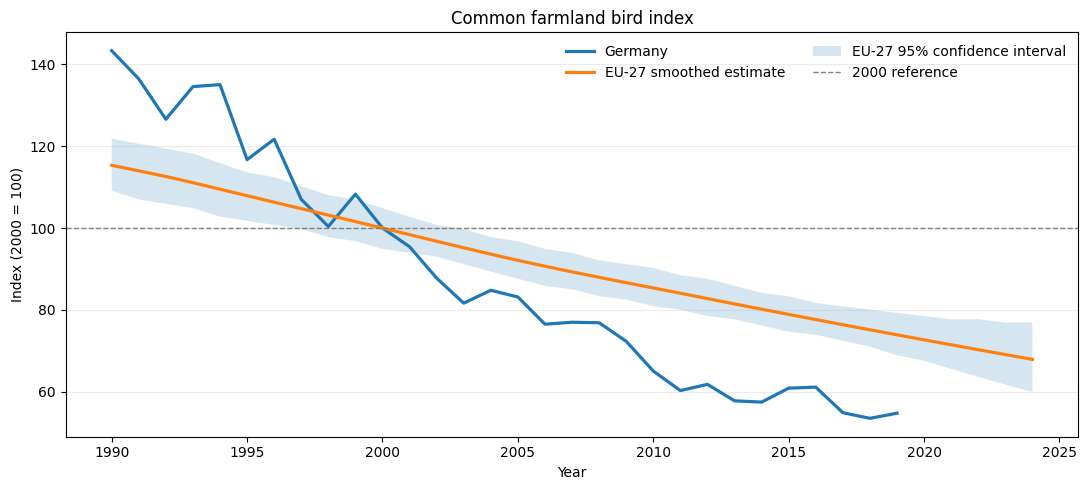

In [ ]:
germany = birds_country.query("country == 'DE'")

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(germany["year"], germany["bird_index"], label="Germany", linewidth=2.3)
ax.plot(
    eu_bird_benchmark["year"],
    eu_bird_benchmark["eu_smoothed"],
    label="EU-27 smoothed estimate",
    linewidth=2.3,
)
ax.fill_between(
    eu_bird_benchmark["year"],
    eu_bird_benchmark["eu_lower_95"],
    eu_bird_benchmark["eu_upper_95"],
    alpha=0.18,
    label="EU-27 95% confidence interval",
)
ax.axhline(100, color="grey", linestyle="--", linewidth=1, label="2000 reference")
ax.set(title="Common farmland bird index", xlabel="Year", ylabel="Index (2000 = 100)")
ax.legend(frameon=False, ncols=2)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


Index explanation:

$$\text{Index}(t) = \frac{\text{estimated bird population in year } t}{\text{estimated bird population in 2000}} \times 100$$


For Germany's Index, in three checking points:
- Year 2000: 100.00
- Year 2010: 65.02
- Year 2019: 54.72


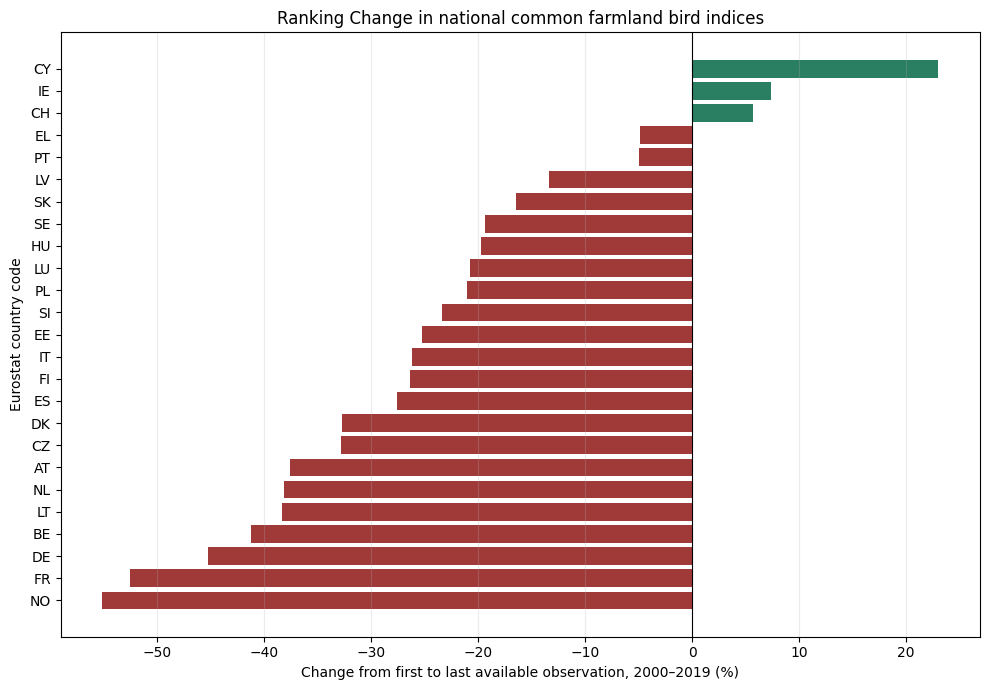

In [ ]:
plot_data = country_trends_2000_2019.sort_values("change_pct")

fig, ax = plt.subplots(figsize=(10, 7))
colors = np.where(plot_data["change_pct"] < 0, "#9F3A38", "#2A7F62")
ax.barh(plot_data["country"], plot_data["change_pct"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(
    title="Ranking Change in national common farmland bird indices",
    xlabel="Change from first to last available observation, 2000–2019 (%)",
    ylabel="Eurostat country code",
)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


Only **CY** *(Cyprus), **IE** (Ireland) and **CH** (Switzerland) observed positive Index of farmland bird population. On a second stage of the study we will look to indicators such as Bio Farming and Pesticede sales, to find correlations with the Index drop of most countries including Germany in comparison with these three.


## 8. Export other DataFrames for possible analsis

The exports keep the data at clearly defined grains:

- `birds_country_long.csv`: one national bird index per country-year;
- `eu_farmland_bird_benchmark.csv`: one EU benchmark row per year;
- `protected_terrestrial_long.csv`: one protected-area percentage per country-year;
- `bird_country_year_panel.csv`: merged descriptive panel, including missing predictors;
- `bird_bird_model_panel.csv`: complete rows for the current protected-area model;
- `country_trends_2000_2019.csv`: country-level trend summary; and
- `data_quality_audit.csv`: parsing and quality-control counts.


In [ ]:
output_dir = Path("outputs/dataframes")
output_dir.mkdir(parents=True, exist_ok=True)

exports = {
    "birds_country_long.csv": birds_country,
    "eu_farmland_bird_benchmark.csv": eu_bird_benchmark,
    "protected_terrestrial_long.csv": protected_terrestrial,
    "bird_country_year_panel.csv": bird_panel,
    "bird_bird_model_panel.csv": bird_model_panel,
    "country_trends_2000_2019.csv": country_trends_2000_2019,
    "data_quality_audit.csv": audit,
}

for filename, dataframe in exports.items():
    dataframe.to_csv(output_dir / filename, index=False)

export_summary = pd.DataFrame(
    {
        "file": exports.keys(),
        "rows": [len(df) for df in exports.values()],
        "columns": [df.shape[1] for df in exports.values()],
    }
)

export_summary
display(bird_panel.head(), bird_model_panel.head())


,country,year,bird_index,bird_flag,eu_unsmoothed,eu_smoothed,eu_lower_95,eu_upper_95,protected_terrestrial_pct,protected_area_flag,bird_minus_eu,bird_change_pct
0,AT,1998,100.00,<NA>,101.79,103.16,108.06,97.78,<NA>,<NA>,-3.16,<NA>
1,AT,1999,102.30,<NA>,102.88,101.58,106.98,96.80,<NA>,<NA>,0.72,2.30
2,AT,2000,98.50,d,99.27,100.00,104.86,94.89,<NA>,<NA>,-1.50,-3.71
3,AT,2001,91.30,d,97.72,98.39,102.79,93.94,<NA>,<NA>,-7.09,-7.31
4,AT,2002,92.80,d,90.89,96.77,100.75,93.01,<NA>,<NA>,-3.97,1.64


,country,year,bird_index,bird_flag,eu_unsmoothed,eu_smoothed,eu_lower_95,eu_upper_95,protected_terrestrial_pct,protected_area_flag,bird_minus_eu,bird_change_pct
0,AT,2011,67.70,d,84.78,84.06,88.47,80.05,27.50,<NA>,-16.36,-3.70
1,AT,2012,68.70,d,82.74,82.75,87.59,78.47,27.90,<NA>,-14.05,1.48
2,AT,2013,63.00,d,79.64,81.44,85.86,77.69,28.00,<NA>,-18.44,-8.30
3,AT,2014,59.80,d,80.93,80.16,84.16,76.15,28.00,<NA>,-20.36,-5.08
4,AT,2015,62.90,d,81.61,78.88,83.32,74.64,28.10,<NA>,-15.98,5.18


## 9. Next stage

The present panel can describe national bird trajectories and their relationship with protected-area coverage. It is not yet a robust agricultural-pressure model because protected-area percentage changes slowly and is only available from 2011.

The next additions should be reshaped with the same function and merged on `country` and `year`:

1. `sdg_02_40`: percentage of utilised agricultural area under organic farming;
2. `aei_fm_salpest09`: Pesticide sales, total kilograms sold
3. `tag00025`: `Utilised agricultural area: thousand hectares, used to convert pesticide sales into kilograms per hectare.

Before fitting a model we need to:

- measure country-year overlap after every join;
- keep flags rather than discarding them silently;
- avoid treating an index as an absolute bird count;
- compare a country-and-year baseline with models containing environmental indicators;
- use a time-based or country-grouped validation split rather than a random row split; and
- describe model results as associations, not causal effects.


## 10. Add agricultural indicators from the Eurostat API

The predictive part uses three environmental indicators:

- **Organic farming:** percentage of utilised agricultural area under organic management (`sdg_02_40`).
- **Pesticide sales:** total kilograms sold (`aei_fm_salpest09`).
- **Utilised agricultural area:** thousand hectares (`tag00025`), used to convert pesticide sales into kilograms per hectare.

Pesticide totals should not be compared directly between large and small countries. The derived intensity is:

$$\text{Pesticide Intensity} = \frac{\text{pesticide sales in kg}}{\text{utilised agricultural area in thousand hectares}} \times 1000$$


The function below reads Eurostat's JSON-stat response using only Python's standard library, so it also works in environments where `requests` is unavailable.


In [ ]:
import json
import urllib.parse
import urllib.request


EUROSTAT_API = "https://ec.europa.eu/eurostat/api/dissemination/statistics/1.0/data"


def fetch_eurostat_jsonstat(dataset_code, filters=None, timeout=90):
    # Fetch a filtered Eurostat dataset and return observations in long format.
    params = {"lang": "en"}
    if filters:
        params.update(filters)
    url = f"{EUROSTAT_API}/{dataset_code}?{urllib.parse.urlencode(params)}"

    with urllib.request.urlopen(url, timeout=timeout) as response:
        payload = json.load(response)

    dimensions = payload["id"]
    sizes = payload["size"]
    dimension_codes = []

    for dimension in dimensions:
        category_index = payload["dimension"][dimension]["category"]["index"]
        if isinstance(category_index, dict):
            ordered_codes = [
                code_value
                for code_value, _ in sorted(category_index.items(), key=lambda item: item[1])
            ]
        else:
            ordered_codes = list(category_index)
        dimension_codes.append(ordered_codes)

    observations = []
    statuses = payload.get("status", {})
    for flat_index_text, value in payload.get("value", {}).items():
        flat_index = int(flat_index_text)
        remaining = flat_index
        coordinates = []
        for size in reversed(sizes):
            coordinates.append(remaining % size)
            remaining //= size
        coordinates.reverse()

        row = {
            dimension: dimension_codes[position][coordinate]
            for position, (dimension, coordinate) in enumerate(
                zip(dimensions, coordinates)
            )
        }
        row["value"] = value
        row["flag"] = statuses.get(flat_index_text, pd.NA)
        observations.append(row)

    result = pd.DataFrame(observations)
    result.attrs["dataset_code"] = dataset_code
    result.attrs["dataset_label"] = payload.get("label", dataset_code)
    result.attrs["source_url"] = url
    return result


organic_raw = fetch_eurostat_jsonstat(
    "sdg_02_40",
    {
        "unit": "PC_UAA",
        "crops": "UAAXK0000",
        "agprdmet": "TOTAL",
    },
)

display(organic_raw.head(10))


pesticide_raw = fetch_eurostat_jsonstat(
    "aei_fm_salpest09",
    {"pesticid": "TOTAL", "unit": "KG"},
)
display(pesticide_raw.head(10))

uaa_raw = fetch_eurostat_jsonstat(
    "tag00025",
    {"crops": "UAA", "strucpro": "MAR_THS_HA"},
)
display(uaa_raw.head(10))

pd.DataFrame(
    {
        "dataset": ["sdg_02_40", "aei_fm_salpest09", "tag00025"],
        "meaning": [
            "Organic farming share",
            "Total pesticide sales",
            "Utilised agricultural area",
        ],
        "retrieved_rows": [len(organic_raw), len(pesticide_raw), len(uaa_raw)],
    }
)


,freq,unit,crops,agprdmet,geo,time,value,flag
0,A,PC_UAA,UAAXK0000,TOTAL,AL,2021,0.09,<NA>
1,A,PC_UAA,UAAXK0000,TOTAL,AL,2022,0.06,<NA>
2,A,PC_UAA,UAAXK0000,TOTAL,AL,2023,0.07,<NA>
3,A,PC_UAA,UAAXK0000,TOTAL,AL,2024,0.07,<NA>
4,A,PC_UAA,UAAXK0000,TOTAL,AT,2000,13.80,<NA>
5,A,PC_UAA,UAAXK0000,TOTAL,AT,2001,14.00,<NA>
6,A,PC_UAA,UAAXK0000,TOTAL,AT,2002,14.50,<NA>
7,A,PC_UAA,UAAXK0000,TOTAL,AT,2003,15.40,<NA>
8,A,PC_UAA,UAAXK0000,TOTAL,AT,2004,16.00,<NA>
9,A,PC_UAA,UAAXK0000,TOTAL,AT,2005,16.70,<NA>


,freq,pesticid,unit,geo,time,value,flag
0,A,TOTAL,KG,AT,2011,3448274,<NA>
1,A,TOTAL,KG,AT,2012,3557023,<NA>
2,A,TOTAL,KG,AT,2013,3097442,<NA>
3,A,TOTAL,KG,AT,2014,3373223,<NA>
4,A,TOTAL,KG,AT,2015,3777617,<NA>
5,A,TOTAL,KG,AT,2016,4361487,<NA>
6,A,TOTAL,KG,AT,2017,4624882,<NA>
7,A,TOTAL,KG,AT,2018,5279544,<NA>
8,A,TOTAL,KG,AT,2019,4954458,<NA>
9,A,TOTAL,KG,AT,2020,5566034,<NA>


,freq,crops,strucpro,geo,time,value,flag
0,A,UAA,MAR_THS_HA,AL,2014,"1,174.30",<NA>
1,A,UAA,MAR_THS_HA,AL,2015,"1,175.00",<NA>
2,A,UAA,MAR_THS_HA,AL,2016,"1,181.70",<NA>
3,A,UAA,MAR_THS_HA,AL,2017,"1,174.10",<NA>
4,A,UAA,MAR_THS_HA,AL,2018,"1,174.00",<NA>
5,A,UAA,MAR_THS_HA,AL,2019,"1,174.10",<NA>
6,A,UAA,MAR_THS_HA,AL,2020,"1,165.70",<NA>
7,A,UAA,MAR_THS_HA,AL,2021,"1,165.60",<NA>
8,A,UAA,MAR_THS_HA,AL,2022,"1,164.40",<NA>
9,A,UAA,MAR_THS_HA,AL,2023,"1,044.60",<NA>


,dataset,meaning,retrieved_rows
0,sdg_02_40,Organic farming share,746
1,aei_fm_salpest09,Total pesticide sales,385
2,tag00025,Utilised agricultural area,460


Let's understand each Eurostat Data set Separately
1. The Eurostat dataset (sdg_02_40) measures the share of agricultural land used for organic farming. Each row represents one geographical area in one year.
| Column     | Meaning                                    | Example                                                            |
| ---------- | ------------------------------------------ | ------------------------------------------------------------------ |
| `freq`     | Reporting frequency                        | `A` = annual                                                       |
| `unit`     | Unit used for the measurement              | `PC_UAA` = percentage of total utilised agricultural area          |
| `crops`    | Agricultural land category included        | `UAAXK0000` = utilised agricultural area excluding kitchen gardens |
| `agprdmet` | Agricultural production method             | `TOTAL` = fully organic and under conversion to organic            |
| `geo`      | Country or European geographical aggregate | `DE` = Germany                                                     |
| `time`     | Observation year                           | `2023`                                                             |
| `value`    | Numeric result                             | `11.16`                                                            |
| `flag`     | Status or quality annotation               | `e` = estimated                                                    |


In [ ]:
#To match the birds data set, rename and select columns

organic_farming = (
    organic_raw
    .rename(
        columns={
            "geo": "country",
            "time": "year",
            "value": "organic_farming_pct",
            "flag": "organic_flag"
        }
    )
    .loc[
        lambda df: df["country"] != "EU27_2020",
        [
            "country",
            "year",
            "organic_farming_pct",
            "organic_flag"
        ]
    ]
    .sort_values(["country", "year"])
    .reset_index(drop=True)
)

organic_farming["year"] = pd.to_numeric(
    organic_farming["year"],
    errors="raise"
).astype(int)

organic_farming.head(20)


,country,year,organic_farming_pct,organic_flag
0,AL,2021,0.09,<NA>
1,AL,2022,0.06,<NA>
2,AL,2023,0.07,<NA>
3,AL,2024,0.07,<NA>
4,AT,2000,13.80,<NA>
5,AT,2001,14.00,<NA>
6,AT,2002,14.50,<NA>
7,AT,2003,15.40,<NA>
8,AT,2004,16.00,<NA>
9,AT,2005,16.70,<NA>


We keep the organic_flag parameter becaus it contains status or comparatability of an observation:
| Flag          | Meaning                                           |
| ------------- | ------------------------------------------------- |
| Missing/`NaN` | No special status flag                            |
| `e`           | Estimated                                         |
| `p`           | Provisional                                       |
| `d`           | Definition differs; consult metadata              |
| `b`           | Break in time series                              |
| `be`          | Both a break in the series and an estimated value |


2. To include the pesticides information in `aei_fm_salpest09` we observe that pesticid: "TOTAL", means this requests total pesticide sales rather than an individual pesticide group such as:

-Fungicides
-Herbicides
-Insecticides
-Molluscicides
-Plant-growth regulators

Using TOTAL prevents multiple pesticide-category rows for the same country and year.

3. In the same workflow we analyze `tag00025`: `Utilised agricultural area: thousand hectares, used to convert pesticide sales into kilograms per hectare.


In [ ]:
print("Pesticide dataset columns:")
print(pesticide_raw.columns.tolist())

print("\nPesticide categories:")
print(pesticide_raw["pesticid"].value_counts(dropna=False))

print("\nPesticide units:")
print(pesticide_raw["unit"].value_counts(dropna=False))


print("\nAgricultural-area dataset columns:")
print(uaa_raw.columns.tolist())

print("\nAgricultural-area categories:")
print(uaa_raw["crops"].value_counts(dropna=False))

print("\nArea measurement types:")
print(uaa_raw["strucpro"].value_counts(dropna=False))


Pesticide dataset columns:
['freq', 'pesticid', 'unit', 'geo', 'time', 'value', 'flag']

Pesticide categories:
pesticid
TOTAL    385
Name: count, dtype: int64

Pesticide units:
unit
KG    385
Name: count, dtype: int64

Agricultural-area dataset columns:
['freq', 'crops', 'strucpro', 'geo', 'time', 'value', 'flag']

Agricultural-area categories:
crops
UAA    460
Name: count, dtype: int64

Area measurement types:
strucpro
MAR_THS_HA    460
Name: count, dtype: int64


In [ ]:
#confirming dimensions
assert pesticide_raw["pesticid"].eq("TOTAL").all()
assert pesticide_raw["unit"].eq("KG").all()

assert uaa_raw["crops"].eq("UAA").all()
assert uaa_raw["strucpro"].eq("MAR_THS_HA").all()


In [ ]:
pesticide_sales = (
    pesticide_raw
    .rename(
        columns={
            "geo": "country",
            "time": "year",
            "value": "pesticide_sales_kg",
            "flag": "pesticide_flag"
        }
    )
    .copy()
)


In [ ]:
#Converting year and kg to numeric

pesticide_sales["year"] = pd.to_numeric(
    pesticide_sales["year"],
    errors="raise"
).astype(int)

pesticide_sales["pesticide_sales_kg"] = pd.to_numeric(
    pesticide_sales["pesticide_sales_kg"],
    errors="coerce"
)


Now in agricultural-area data


In [ ]:
agricultural_area = (
    uaa_raw
    .rename(
        columns={
            "geo": "country",
            "time": "year",
            "value": "uaa_thousand_ha",
            "flag": "uaa_flag"
        }
    )
    .copy()
)


In [ ]:
agricultural_area["year"] = pd.to_numeric(
    agricultural_area["year"],
    errors="raise"
).astype(int)

agricultural_area["uaa_thousand_ha"] = pd.to_numeric(
    agricultural_area["uaa_thousand_ha"],
    errors="coerce"
)


Both data set might contain
EU27_2020
EA20
EFTA
Which are group of countries and not countries, and they shouldn't enter in a country level model


In [ ]:
AGGREGATE_GEOS = {
    "EU27_2020",
    "EU28",
    "EA19",
    "EA20",
    "EFTA",
    "EEA30_2007",
    "CC4_2020",
    "CC3_2007"
}


In [ ]:
pesticide_sales = pesticide_sales.loc[
    ~pesticide_sales["country"].isin(AGGREGATE_GEOS),
    [
        "country",
        "year",
        "pesticide_sales_kg",
        "pesticide_flag"
    ]
].copy()

agricultural_area = agricultural_area.loc[
    ~agricultural_area["country"].isin(AGGREGATE_GEOS),
    [
        "country",
        "year",
        "uaa_thousand_ha",
        "uaa_flag"
    ]
].copy()


Checking missing values, flags and duplicates


In [ ]:
pesticide_audit = pd.Series({
    "rows": len(pesticide_sales),
    "countries": pesticide_sales["country"].nunique(),
    "first_year": pesticide_sales["year"].min(),
    "last_year": pesticide_sales["year"].max(),
    "missing_values": pesticide_sales["pesticide_sales_kg"].isna().sum(),
    "flagged_values": pesticide_sales["pesticide_flag"].notna().sum(),
    "duplicate_keys": pesticide_sales.duplicated(
        ["country", "year"]
    ).sum()
})

uaa_audit = pd.Series({
    "rows": len(agricultural_area),
    "countries": agricultural_area["country"].nunique(),
    "first_year": agricultural_area["year"].min(),
    "last_year": agricultural_area["year"].max(),
    "missing_values": agricultural_area["uaa_thousand_ha"].isna().sum(),
    "flagged_values": agricultural_area["uaa_flag"].notna().sum(),
    "duplicate_keys": agricultural_area.duplicated(
        ["country", "year"]
    ).sum()
})

display(
    pd.concat(
        {
            "pesticide_sales": pesticide_audit,
            "agricultural_area": uaa_audit
        },
        axis=1
    ).T
)


,rows,countries,first_year,last_year,missing_values,flagged_values,duplicate_keys
pesticide_sales,385,32,2011,2024,0,1,0
agricultural_area,448,38,2013,2024,0,32,0


In [ ]:
#inspecting flags
display(
    pesticide_sales["pesticide_flag"]
    .value_counts(dropna=False)
    .rename_axis("flag")
    .reset_index(name="observations")
)

display(
    agricultural_area["uaa_flag"]
    .value_counts(dropna=False)
    .rename_axis("flag")
    .reset_index(name="observations")
)


,flag,observations
0,<NA>,384
1,b,1


,flag,observations
0,<NA>,416
1,e,20
2,p,11
3,b,1


Checking duplicates


In [ ]:
pesticide_duplicates = pesticide_sales.loc[
    pesticide_sales.duplicated(
        ["country", "year"],
        keep=False
    )
]

uaa_duplicates = agricultural_area.loc[
    agricultural_area.duplicated(
        ["country", "year"],
        keep=False
    )
]

display(pesticide_duplicates.sum())
display(uaa_duplicates.sum())


,0
country,0
year,0
pesticide_sales_kg,0
pesticide_flag,0


,0
country,0
year,0
uaa_thousand_ha,0.00
uaa_flag,0


Checking country/year matches in both data sets


In [ ]:
merge_diagnostic = pesticide_sales.merge(
    agricultural_area,
    on=["country", "year"],
    how="outer",
    indicator=True,
    validate="one_to_one"
)

display(
    merge_diagnostic["_merge"]
    .value_counts()
    .rename_axis("merge_status")
    .reset_index(name="rows")
)


,merge_status,rows
0,both,335
1,right_only,113
2,left_only,50


So we will be able to merge with 335 country/year matching rows in order to obtain information about the pesticide intensity.


In [ ]:
pesticide_intensity = pesticide_sales.merge(
    agricultural_area,
    on=["country", "year"],
    how="inner",
    validate="one_to_one"
)
pesticide_intensity["uaa_ha"] = (
    pesticide_intensity["uaa_thousand_ha"] * 1000
)
pesticide_intensity["pesticide_kg_per_ha"] = (
    pesticide_intensity["pesticide_sales_kg"] / pesticide_intensity["uaa_ha"]
)
pesticide_intensity.head(20)


,country,year,pesticide_sales_kg,pesticide_flag,uaa_thousand_ha,uaa_flag,uaa_ha,pesticide_kg_per_ha
0,AT,2013,3097442,<NA>,"2,862.44",<NA>,"2,862,440.00",1.08
1,AT,2014,3373223,<NA>,"2,716.16",<NA>,"2,716,160.00",1.24
2,AT,2015,3777617,<NA>,"2,720.40",<NA>,"2,720,400.00",1.39
3,AT,2016,4361487,<NA>,"2,688.83",<NA>,"2,688,830.00",1.62
4,AT,2017,4624882,<NA>,"2,655.56",<NA>,"2,655,560.00",1.74
5,AT,2018,5279544,<NA>,"2,653.84",<NA>,"2,653,840.00",1.99
6,AT,2019,4954458,<NA>,"2,652.22",<NA>,"2,652,220.00",1.87
7,AT,2020,5566034,<NA>,"2,646.96",<NA>,"2,646,960.00",2.10
8,AT,2021,5790560,<NA>,"2,602.49",<NA>,"2,602,490.00",2.23
9,AT,2022,6068732,<NA>,"2,599.51",<NA>,"2,599,510.00",2.33


In [ ]:
#Checking for invalid input data
invalid_pesticide_data = (
    pesticide_intensity["pesticide_sales_kg"].isna()
    | pesticide_intensity["pesticide_sales_kg"].lt(0)
    | pesticide_intensity["uaa_ha"].isna()
    | pesticide_intensity["uaa_ha"].le(0)
)

display(
    pesticide_intensity.loc[
        invalid_pesticide_data,
        [
            "country",
            "year",
            "pesticide_sales_kg",
            "uaa_thousand_ha",
            "pesticide_flag",
            "uaa_flag"
        ]
    ]
)


,country,year,pesticide_sales_kg,uaa_thousand_ha,pesticide_flag,uaa_flag


Alles gut!


Creating the final Pesticides Intensity Data Frame


In [ ]:
pesticide_intensity_ready = (
    pesticide_intensity[
        [
            "country",
            "year",
            "pesticide_sales_kg",
            "uaa_thousand_ha",
            "uaa_ha",
            "pesticide_kg_per_ha",
            "pesticide_flag",
            "uaa_flag"
        ]
    ]
    .sort_values(["country", "year"])
    .reset_index(drop=True)
)

display(pesticide_intensity_ready.head(10))

print("Rows:", len(pesticide_intensity_ready))
print(
    "Countries:",
    pesticide_intensity_ready["country"].nunique()
)
print(
    "Years:",
    pesticide_intensity_ready["year"].min(),
    "to",
    pesticide_intensity_ready["year"].max()
)
print(
    "Missing intensity:",
    pesticide_intensity_ready[
        "pesticide_kg_per_ha"
    ].isna().sum()
)
print(
    "Duplicate country-years:",
    pesticide_intensity_ready.duplicated(
        ["country", "year"]
    ).sum()
)


,country,year,pesticide_sales_kg,uaa_thousand_ha,uaa_ha,pesticide_kg_per_ha,pesticide_flag,uaa_flag
0,AT,2013,3097442,"2,862.44","2,862,440.00",1.08,<NA>,<NA>
1,AT,2014,3373223,"2,716.16","2,716,160.00",1.24,<NA>,<NA>
2,AT,2015,3777617,"2,720.40","2,720,400.00",1.39,<NA>,<NA>
3,AT,2016,4361487,"2,688.83","2,688,830.00",1.62,<NA>,<NA>
4,AT,2017,4624882,"2,655.56","2,655,560.00",1.74,<NA>,<NA>
5,AT,2018,5279544,"2,653.84","2,653,840.00",1.99,<NA>,<NA>
6,AT,2019,4954458,"2,652.22","2,652,220.00",1.87,<NA>,<NA>
7,AT,2020,5566034,"2,646.96","2,646,960.00",2.10,<NA>,<NA>
8,AT,2021,5790560,"2,602.49","2,602,490.00",2.23,<NA>,<NA>
9,AT,2022,6068732,"2,599.51","2,599,510.00",2.33,<NA>,<NA>


Rows: 335
Countries: 32
Years: 2013 to 2024
Missing intensity: 0
Duplicate country-years: 0


## 11. Create the Model Ready Data Frame


Now we have these three Data Frames


*   birds_country
*   organic_farming
*   pesticide_intensity_ready


We start with the birds_country data frame and using left joins because the bird index is your target variable. This preserves all bird observations and shows where explanatory variables are unavailable.


In [ ]:
birds_environment_panel = (
    birds_country
    .merge(
        organic_farming[
            [
                "country",
                "year",
                "organic_farming_pct",
                "organic_flag"
            ]
        ],
        on=["country", "year"],
        how="left",
        validate="one_to_one"
    )
    .merge(
        pesticide_intensity_ready,
        on=["country", "year"],
        how="left",
        validate="one_to_one"
    )
    .sort_values(["country", "year"])
    .reset_index(drop=True)
)


In [ ]:
display(birds_environment_panel.head(10))

print("Panel shape:", birds_environment_panel.shape)

display(
    birds_environment_panel[
        [
            "bird_index",
            "organic_farming_pct",
            "pesticide_kg_per_ha"
        ]
    ]
    .isna()
    .sum()
    .rename("missing_values")
    .to_frame()
)


,country,year,bird_index,bird_flag,organic_farming_pct,organic_flag,pesticide_sales_kg,uaa_thousand_ha,uaa_ha,pesticide_kg_per_ha,pesticide_flag,uaa_flag
0,AT,1998,100.00,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AT,1999,102.30,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AT,2000,98.50,d,13.80,<NA>,NaN,NaN,NaN,NaN,NaN,NaN
3,AT,2001,91.30,d,14.00,<NA>,NaN,NaN,NaN,NaN,NaN,NaN
4,AT,2002,92.80,d,14.50,<NA>,NaN,NaN,NaN,NaN,NaN,NaN
5,AT,2003,87.80,d,15.40,<NA>,NaN,NaN,NaN,NaN,NaN,NaN
6,AT,2004,90.40,d,16.00,<NA>,NaN,NaN,NaN,NaN,NaN,NaN
7,AT,2005,92.50,d,16.70,<NA>,NaN,NaN,NaN,NaN,NaN,NaN
8,AT,2006,85.00,d,16.70,<NA>,NaN,NaN,NaN,NaN,NaN,NaN
9,AT,2007,82.10,d,17.00,<NA>,NaN,NaN,NaN,NaN,NaN,NaN


Panel shape: (643, 12)


,missing_values
bird_index,0
organic_farming_pct,152
pesticide_kg_per_ha,420


DATA SET FOR THE MODEL


In [ ]:
model_data = (
    birds_environment_panel
    .dropna(
        subset=[
            "bird_index",
            "organic_farming_pct",
            "pesticide_kg_per_ha"
        ]
    )
    .reset_index(drop=True)
)
display(model_data.head(10))
model_data.info()


,country,year,bird_index,bird_flag,organic_farming_pct,organic_flag,pesticide_sales_kg,uaa_thousand_ha,uaa_ha,pesticide_kg_per_ha,pesticide_flag,uaa_flag
0,AT,2013,63.00,d,18.40,<NA>,"3,097,442.00","2,862.44","2,862,440.00",1.08,<NA>,<NA>
1,AT,2014,59.80,d,19.35,<NA>,"3,373,223.00","2,716.16","2,716,160.00",1.24,<NA>,<NA>
2,AT,2015,62.90,d,20.30,<NA>,"3,777,617.00","2,720.40","2,720,400.00",1.39,<NA>,<NA>
3,AT,2016,58.40,d,21.25,<NA>,"4,361,487.00","2,688.83","2,688,830.00",1.62,<NA>,<NA>
4,AT,2017,60.70,d,23.37,<NA>,"4,624,882.00","2,655.56","2,655,560.00",1.74,<NA>,<NA>
5,AT,2018,55.20,d,24.08,<NA>,"5,279,544.00","2,653.84","2,653,840.00",1.99,<NA>,<NA>
6,AT,2019,61.50,d,25.33,<NA>,"4,954,458.00","2,652.22","2,652,220.00",1.87,<NA>,<NA>
7,AT,2020,61.70,d,25.69,<NA>,"5,566,034.00","2,646.96","2,646,960.00",2.10,<NA>,<NA>
8,BE,2013,72.88,<NA>,4.67,<NA>,"6,335,282.00","1,338.57","1,338,570.00",4.73,<NA>,<NA>
9,BE,2014,70.43,<NA>,5.00,<NA>,"7,180,178.00","1,333.40","1,333,400.00",5.38,<NA>,<NA>


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 218 entries, 0 to 217
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   country              218 non-null    object 
 1   year                 218 non-null    int64  
 2   bird_index           218 non-null    Float64
 3   bird_flag            87 non-null     string 
 4   organic_farming_pct  218 non-null    float64
 5   organic_flag         12 non-null     object 
 6   pesticide_sales_kg   218 non-null    float64
 7   uaa_thousand_ha      218 non-null    float64
 8   uaa_ha               218 non-null    float64
 9   pesticide_kg_per_ha  218 non-null    float64
 10  pesticide_flag       0 non-null      object 
 11  uaa_flag             6 non-null      object 
dtypes: Float64(1), float64(5), int64(1), object(4), string(1)
memory usage: 20.8+ KB


One scientific limitation should remain explicit: pesticide_kg_per_ha represents pesticide sales per agricultural hectare, not pesticides actually applied in that country-year. Sales may differ from use because of storage, trade, reporting practices and non-agricultural professional applications. It is a reasonable national pressure proxy, but not a direct exposure measurement.


# 12. End-to-end machine learning: two regression studies

The modelling question is now deliberately divided into two parts:

1. **Bird-history model:** how well can a country's known bird trajectory predict its index in the following year?
2. **Environmental extension:** on the smaller set of matched country-years, do organic farming, pesticide intensity, protected terrestrial area and nitrogen-fertiliser intensity improve predictions beyond bird history alone?

This distinction solves two different problems. The first model uses the largest defensible sample. The second preserves the environmental question. For a fair environmental comparison, history-only and environment-extended models will be evaluated on **exactly the same rows and years**.

The target is continuous, so this is a regression task. The primary metric is **MAE** (mean absolute error, in bird-index points). RMSE, R² and the percentage of predictions within ±5 index points are reported as complementary measures. Classification accuracy is not an appropriate primary metric for a continuous target.


## 12.1 Add one relevant Eurostat pressure indicator

The additional dataset is **`aei_fm_usefert` — consumption of inorganic fertilisers in agriculture**. Nitrogen fertiliser is ecologically relevant because intensive nutrient inputs can alter plant and invertebrate communities on which farmland birds depend. Eurostat reports nutrient mass in tonnes; dividing nitrogen tonnes by utilised agricultural area produces a comparable **kg N per hectare** indicator.

This remains a national pressure proxy rather than a direct measurement of bird exposure. Eurostat also notes that national fertiliser data sources are not fully harmonised. The indicator is therefore tested for incremental predictive value, not interpreted as causal proof.

Sources: [Eurostat mineral fertiliser indicator](https://ec.europa.eu/eurostat/statistics-explained/index.php?title=Agri-environmental_indicator_-_mineral_fertiliser_consumption) and [Eurostat dataset `aei_fm_usefert`](https://ec.europa.eu/eurostat/databrowser/view/aei_fm_usefert/default/table?lang=en).


In [ ]:
fertilizer_raw = fetch_eurostat_jsonstat(
    "aei_fm_usefert",
    {"nutrient": "N", "unit": "T"},
)

display(fertilizer_raw.head(10))

# Keep only national observations represented in the bird dataset. This removes
# EU aggregates and NUTS-2 regional rows without relying on code length alone.
fertilizer_nitrogen = (
    fertilizer_raw
    .loc[
        fertilizer_raw["geo"].isin(birds_country["country"].unique()),
        ["geo", "time", "value", "flag"],
    ]
    .rename(
        columns={
            "geo": "country",
            "time": "year",
            "value": "nitrogen_fertilizer_tonnes",
            "flag": "fertilizer_flag",
        }
    )
    .assign(year=lambda df: pd.to_numeric(df["year"], errors="raise").astype(int))
    .sort_values(["country", "year"], ignore_index=True)
)

fertilizer_intensity_ready = (
    fertilizer_nitrogen
    .merge(
        agricultural_area[["country", "year", "uaa_thousand_ha"]],
        on=["country", "year"],
        how="inner",
        validate="one_to_one",
    )
    .assign(
        nitrogen_fertilizer_kg_per_ha=lambda df:
            (df["nitrogen_fertilizer_tonnes"] * 1000)
            / (df["uaa_thousand_ha"] * 1000)
    )
)

fertilizer_intensity_ready.loc[
    fertilizer_intensity_ready["uaa_thousand_ha"].le(0),
    "nitrogen_fertilizer_kg_per_ha",
] = np.nan

display(fertilizer_intensity_ready.head(10))
pd.Series({
    "raw rows": len(fertilizer_raw),
    "national nitrogen rows": len(fertilizer_nitrogen),
    "intensity rows after UAA merge": len(fertilizer_intensity_ready),
    "countries": fertilizer_intensity_ready["country"].nunique(),
    "first year": fertilizer_intensity_ready["year"].min(),
    "last year": fertilizer_intensity_ready["year"].max(),
    "missing intensity": fertilizer_intensity_ready["nitrogen_fertilizer_kg_per_ha"].isna().sum(),
}, name="value").to_frame()


,freq,nutrient,unit,geo,time,value,flag
0,A,N,T,AL,2000,"13,943.00",<NA>
1,A,N,T,AL,2001,"18,131.00",<NA>
2,A,N,T,AL,2002,"18,187.00",<NA>
3,A,N,T,AL,2003,"20,028.00",<NA>
4,A,N,T,AL,2004,"16,511.00",<NA>
5,A,N,T,AL,2005,"17,281.00",<NA>
6,A,N,T,AL,2006,"14,584.00",<NA>
7,A,N,T,AL,2007,"14,803.00",<NA>
8,A,N,T,AL,2008,"13,442.00",<NA>
9,A,N,T,AL,2009,"15,631.00",<NA>


,country,year,nitrogen_fertilizer_tonnes,fertilizer_flag,uaa_thousand_ha,nitrogen_fertilizer_kg_per_ha
0,AT,2013,"110,626.00",<NA>,"2,862.44",38.65
1,AT,2014,"121,562.00",<NA>,"2,716.16",44.76
2,AT,2015,"124,078.00",<NA>,"2,720.40",45.61
3,AT,2016,"132,031.00",<NA>,"2,688.83",49.10
4,AT,2017,"111,884.00",<NA>,"2,655.56",42.13
5,AT,2018,"100,096.00",<NA>,"2,653.84",37.72
6,AT,2019,"102,812.00",<NA>,"2,652.22",38.76
7,AT,2020,"117,321.00",<NA>,"2,646.96",44.32
8,AT,2021,"94,319.00",<NA>,"2,602.49",36.24
9,AT,2022,"97,561.00",dp,"2,599.51",37.53


,value
raw rows,2598
national nitrogen rows,624
intensity rows after UAA merge,294
countries,25
first year,2013
last year,2024
missing intensity,0


## 12.2 Leakage-safe bird-history features and next-year target

Each row represents information available at the end of year *t*. The target is the bird index in year *t+1*. Lags are accepted only when the calendar years are consecutive; this prevents a missing year from being treated as a one-year lag.

The present bird index is retained because it is known at prediction time. It also creates a demanding **persistence baseline**: “next year's index equals this year's index.” Any useful ML model should be compared against that baseline.


In [ ]:
bird_ml = birds_country[["country", "year", "bird_index", "bird_flag"]].copy()
bird_ml = bird_ml.sort_values(["country", "year"], ignore_index=True)
country_group = bird_ml.groupby("country", sort=False)

bird_ml["lag_year_1"] = country_group["year"].shift(1)
bird_ml["lag_year_2"] = country_group["year"].shift(2)
bird_ml["next_year"] = country_group["year"].shift(-1)
bird_ml["bird_lag_1"] = country_group["bird_index"].shift(1)
bird_ml["bird_lag_2"] = country_group["bird_index"].shift(2)
bird_ml["target_next_bird_index"] = country_group["bird_index"].shift(-1)

bird_ml.loc[bird_ml["lag_year_1"].ne(bird_ml["year"] - 1), "bird_lag_1"] = np.nan
bird_ml.loc[bird_ml["lag_year_2"].ne(bird_ml["year"] - 2), "bird_lag_2"] = np.nan
bird_ml.loc[bird_ml["next_year"].ne(bird_ml["year"] + 1), "target_next_bird_index"] = np.nan

bird_ml["bird_change_1y"] = bird_ml["bird_index"] - bird_ml["bird_lag_1"]
bird_ml["bird_recent_slope"] = (bird_ml["bird_index"] - bird_ml["bird_lag_2"]) / 2
bird_ml["bird_mean_3y"] = bird_ml[["bird_index", "bird_lag_1", "bird_lag_2"]].mean(axis=1)
bird_ml["bird_std_3y"] = bird_ml[["bird_index", "bird_lag_1", "bird_lag_2"]].std(axis=1)

history_features = [
    "year", "country", "bird_index", "bird_lag_1", "bird_lag_2",
    "bird_change_1y", "bird_recent_slope", "bird_mean_3y", "bird_std_3y",
]
target_column = "target_next_bird_index"

bird_history_model_data = (
    bird_ml
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=history_features + [target_column])
    .reset_index(drop=True)
)

display(bird_history_model_data.head())
pd.Series({
    "rows": len(bird_history_model_data),
    "countries": bird_history_model_data["country"].nunique(),
    "first predictor year": bird_history_model_data["year"].min(),
    "last predictor year": bird_history_model_data["year"].max(),
}, name="value").to_frame()


,country,year,bird_index,bird_flag,lag_year_1,lag_year_2,next_year,bird_lag_1,bird_lag_2,target_next_bird_index,bird_change_1y,bird_recent_slope,bird_mean_3y,bird_std_3y
0,AT,2000,98.50,d,"1,999.00","1,998.00","2,001.00",102.30,100.00,91.30,-3.80,-0.75,100.27,1.91
1,AT,2001,91.30,d,"2,000.00","1,999.00","2,002.00",98.50,102.30,92.80,-7.20,-5.50,97.37,5.59
2,AT,2002,92.80,d,"2,001.00","2,000.00","2,003.00",91.30,98.50,87.80,1.50,-2.85,94.20,3.80
3,AT,2003,87.80,d,"2,002.00","2,001.00","2,004.00",92.80,91.30,90.40,-5.00,-1.75,90.63,2.57
4,AT,2004,90.40,d,"2,003.00","2,002.00","2,005.00",87.80,92.80,92.50,2.60,-1.20,90.33,2.50


,value
rows,568
countries,25
first predictor year,1992
last predictor year,2023


## 12.3 Construct the environmental extension

The left-joined panel remains useful for auditing coverage. For modelling, complete rows are required. The environmental model adds four interpretable national indicators: organic share of UAA, pesticide sales per UAA, terrestrial protected-area percentage, and nitrogen-fertiliser consumption per UAA.

Raw pesticide sales and raw agricultural area are not added alongside their ratio: doing so would introduce redundant scale information and make interpretation less clear.


In [ ]:
environmental_ml_panel = (
    bird_ml
    .merge(
        organic_farming[["country", "year", "organic_farming_pct"]],
        on=["country", "year"], how="left", validate="one_to_one",
    )
    .merge(
        pesticide_intensity_ready[["country", "year", "pesticide_kg_per_ha"]],
        on=["country", "year"], how="left", validate="one_to_one",
    )
    .merge(
        protected_terrestrial[["country", "year", "protected_terrestrial_pct"]],
        on=["country", "year"], how="left", validate="one_to_one",
    )
    .merge(
        fertilizer_intensity_ready[["country", "year", "nitrogen_fertilizer_kg_per_ha"]],
        on=["country", "year"], how="left", validate="one_to_one",
    )
    .sort_values(["country", "year"], ignore_index=True)
)

environment_features = history_features + [
    "organic_farming_pct",
    "pesticide_kg_per_ha",
    "protected_terrestrial_pct",
    "nitrogen_fertilizer_kg_per_ha",
]

environment_model_data = (
    environmental_ml_panel
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=environment_features + [target_column])
    .reset_index(drop=True)
)

coverage_table = pd.DataFrame({
    "variable": [
        "bird target", "organic farming", "pesticide intensity",
        "protected terrestrial area", "nitrogen fertiliser intensity",
    ],
    "available rows in environmental panel": [
        environmental_ml_panel[target_column].notna().sum(),
        environmental_ml_panel["organic_farming_pct"].notna().sum(),
        environmental_ml_panel["pesticide_kg_per_ha"].notna().sum(),
        environmental_ml_panel["protected_terrestrial_pct"].notna().sum(),
        environmental_ml_panel["nitrogen_fertilizer_kg_per_ha"].notna().sum(),
    ],
})

display(coverage_table)
display(environment_model_data.head())
pd.Series({
    "complete rows": len(environment_model_data),
    "countries": environment_model_data["country"].nunique(),
    "first predictor year": environment_model_data["year"].min(),
    "last predictor year": environment_model_data["year"].max(),
}, name="value").to_frame()


,variable,available rows in environmental panel
0,bird target,618
1,organic farming,491
2,pesticide intensity,223
3,protected terrestrial area,268
4,nitrogen fertiliser intensity,241


,country,year,bird_index,bird_flag,lag_year_1,lag_year_2,next_year,bird_lag_1,bird_lag_2,target_next_bird_index,bird_change_1y,bird_recent_slope,bird_mean_3y,bird_std_3y,organic_farming_pct,pesticide_kg_per_ha,protected_terrestrial_pct,nitrogen_fertilizer_kg_per_ha
0,AT,2013,63.00,d,"2,012.00","2,011.00","2,014.00",68.70,67.70,59.80,-5.70,-2.35,66.47,3.04,18.40,1.08,28.00,38.65
1,AT,2014,59.80,d,"2,013.00","2,012.00","2,015.00",63.00,68.70,62.90,-3.20,-4.45,63.83,4.51,19.35,1.24,28.00,44.76
2,AT,2015,62.90,d,"2,014.00","2,013.00","2,016.00",59.80,63.00,58.40,3.10,-0.05,61.90,1.82,20.30,1.39,28.10,45.61
3,AT,2016,58.40,d,"2,015.00","2,014.00","2,017.00",62.90,59.80,60.70,-4.50,-0.70,60.37,2.30,21.25,1.62,28.10,49.10
4,AT,2017,60.70,d,"2,016.00","2,015.00","2,018.00",58.40,62.90,55.20,2.30,-1.10,60.67,2.25,23.37,1.74,28.10,42.13


,value
complete rows,177
countries,22
first predictor year,2013
last predictor year,2023


## 12.4 Modelling and cross-validation strategy

The final test set is temporal: years from 2019 onward are never used for fitting or hyperparameter selection. Within the earlier training period, expanding-window validation trains on past years and validates on a later year. This is more faithful to forecasting than a random split.

Models tested:

- **Persistence baseline:** next year equals the current year.
- **Ridge:** regularised linear benchmark; useful with a small sample and correlated features.
- **Random Forest:** nonlinear bagging ensemble.
- **Extra Trees:** a more randomised ensemble that can reduce variance.
- **Gradient Boosting:** sequentially corrects earlier errors.
- **Histogram Gradient Boosting:** regularised boosting implementation suitable for nonlinear relations.

Hyperparameters are selected using cross-validated MAE. Model complexity is kept deliberately modest because country-year observations are correlated and the environmental sample is small.


In [ ]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

TEST_START_YEAR = 2019


def make_temporal_cv(frame, minimum_training_years=3, maximum_splits=4):
    # Expanding-window CV: every validation observation occurs after training.
    years = np.array(sorted(frame["year"].unique()))
    candidate_validation_years = years[minimum_training_years:]
    candidate_validation_years = candidate_validation_years[-maximum_splits:]
    splits = []
    for validation_year in candidate_validation_years:
        train_idx = np.flatnonzero(frame["year"].to_numpy() < validation_year)
        valid_idx = np.flatnonzero(frame["year"].to_numpy() == validation_year)
        if len(train_idx) and len(valid_idx):
            splits.append((train_idx, valid_idx))
    if len(splits) < 2:
        raise ValueError("Not enough distinct training years for temporal cross-validation.")
    return splits


def make_preprocessor(feature_names):
    numeric = [name for name in feature_names if name != "country"]
    return ColumnTransformer(
        transformers=[
            ("numeric", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]), numeric),
            ("country", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]), ["country"]),
        ],
        sparse_threshold=0,
    )


MODEL_SPECS = {
    "Ridge": (
        Ridge(),
        {"model__alpha": [0.1, 1.0, 10.0, 100.0]},
    ),
    "Random forest": (
        RandomForestRegressor(random_state=42, n_jobs=1),
        {
            "model__n_estimators": [300],
            "model__max_depth": [3, None],
            "model__min_samples_leaf": [2, 5],
            "model__max_features": ["sqrt", 0.8],
        },
    ),
    "Extra Trees": (
        ExtraTreesRegressor(random_state=42, n_jobs=1),
        {
            "model__n_estimators": [300],
            "model__max_depth": [3, None],
            "model__min_samples_leaf": [2, 5],
            "model__max_features": ["sqrt", 0.8],
        },
    ),
    "Gradient Boosting": (
        GradientBoostingRegressor(random_state=42, loss="huber"),
        {
            "model__n_estimators": [100, 250],
            "model__learning_rate": [0.03, 0.08],
            "model__max_depth": [1, 2],
            "model__min_samples_leaf": [3, 6],
        },
    ),
    "Histogram Gradient Boosting": (
        HistGradientBoostingRegressor(random_state=42, loss="absolute_error"),
        {
            "model__learning_rate": [0.03, 0.08],
            "model__max_leaf_nodes": [7, 15],
            "model__l2_regularization": [0.0, 1.0],
        },
    ),
}


def evaluate_regression_study(data, features, study_name):
    train = data.loc[data["year"] < TEST_START_YEAR].reset_index(drop=True)
    test = data.loc[data["year"] >= TEST_START_YEAR].reset_index(drop=True)
    if train.empty or test.empty:
        raise ValueError(f"{study_name}: temporal train or test set is empty")

    X_train, y_train = train[features], train[target_column]
    X_test, y_test = test[features], test[target_column]
    temporal_cv = make_temporal_cv(train)
    preprocessor = make_preprocessor(features)

    fitted = {}
    rows = []

    baseline_prediction = test["bird_index"].to_numpy()
    rows.append({
        "study": study_name,
        "model": "Persistence baseline",
        "cv_mae": np.nan,
        "test_mae": mean_absolute_error(y_test, baseline_prediction),
        "test_rmse": mean_squared_error(y_test, baseline_prediction) ** 0.5,
        "test_r2": r2_score(y_test, baseline_prediction),
        "within_5_points": np.mean(np.abs(y_test.to_numpy() - baseline_prediction) <= 5),
    })

    for model_name, (estimator, parameter_grid) in MODEL_SPECS.items():
        pipeline = Pipeline([
            ("preprocess", clone(preprocessor)),
            ("model", clone(estimator)),
        ])
        search = GridSearchCV(
            pipeline,
            param_grid=parameter_grid,
            scoring="neg_mean_absolute_error",
            cv=temporal_cv,
            n_jobs=1,
            refit=True,
        )
        search.fit(X_train, y_train)
        prediction = search.predict(X_test)
        fitted[model_name] = search
        rows.append({
            "study": study_name,
            "model": model_name,
            "cv_mae": -search.best_score_,
            "test_mae": mean_absolute_error(y_test, prediction),
            "test_rmse": mean_squared_error(y_test, prediction) ** 0.5,
            "test_r2": r2_score(y_test, prediction),
            "within_5_points": np.mean(np.abs(y_test.to_numpy() - prediction) <= 5),
        })

    results = pd.DataFrame(rows).sort_values("test_mae", ignore_index=True)
    split = pd.Series({
        "study": study_name,
        "training rows": len(train),
        "test rows": len(test),
        "training countries": train["country"].nunique(),
        "test countries": test["country"].nunique(),
        "train years": f'{train["year"].min()}–{train["year"].max()}',
        "test years": f'{test["year"].min()}–{test["year"].max()}',
        "temporal CV folds": len(temporal_cv),
    })
    return results, fitted, train, test, split


## 12.5 Model 1 — full bird-history forecasting

This is the larger-sample model. It establishes how much can be predicted from the trajectory itself before environmental variables are introduced.


In [ ]:
history_results, history_fitted, history_train, history_test, history_split = (
    evaluate_regression_study(
        bird_history_model_data,
        history_features,
        "Model 1: full bird history",
    )
)

display(history_split.to_frame("value"))
display(history_results.style.format({
    "cv_mae": "{:.2f}", "test_mae": "{:.2f}", "test_rmse": "{:.2f}",
    "test_r2": "{:.3f}", "within_5_points": "{:.1%}",
}))


,value
study,Model 1: full bird history
training rows,495
test rows,73
training countries,25
test countries,22
train years,1992–2018
test years,2019–2023
temporal CV folds,4


,study,model,cv_mae,test_mae,test_rmse,test_r2,within_5_points
0,Model 1: full bird history,Ridge,4.08,5.65,9.51,0.752,65.8%
1,Model 1: full bird history,Gradient Boosting,4.35,5.71,9.54,0.751,60.3%
2,Model 1: full bird history,Extra Trees,4.17,5.84,9.39,0.759,54.8%
3,Model 1: full bird history,Random forest,4.10,6.03,9.68,0.744,58.9%
4,Model 1: full bird history,Persistence baseline,nan,6.14,10.08,0.722,67.1%
5,Model 1: full bird history,Histogram Gradient Boosting,4.73,6.21,9.60,0.748,54.8%


## 12.6 Model 2 — fair environmental comparison

Two versions are fitted on the same environmental complete-case rows:

- **Matched history-only:** only bird-history predictors.
- **Matched environmental extension:** the same predictors plus the four environmental indicators.

This is the valid test of incremental environmental information. Comparing the full-history result directly with the environmental result would confound feature effects with different samples.


In [ ]:
matched_history_results, matched_history_fitted, matched_train, matched_test, matched_split = (
    evaluate_regression_study(
        environment_model_data,
        history_features,
        "Model 2A: matched history only",
    )
)

environment_results, environment_fitted, environment_train, environment_test, environment_split = (
    evaluate_regression_study(
        environment_model_data,
        environment_features,
        "Model 2B: environmental extension",
    )
)

fair_comparison = pd.concat(
    [matched_history_results, environment_results],
    ignore_index=True,
).sort_values(["study", "test_mae"], ignore_index=True)

display(environment_split.to_frame("value"))
display(fair_comparison.style.format({
    "cv_mae": "{:.2f}", "test_mae": "{:.2f}", "test_rmse": "{:.2f}",
    "test_r2": "{:.3f}", "within_5_points": "{:.1%}",
}))


,value
study,Model 2B: environmental extension
training rows,115
test rows,62
training countries,22
test countries,19
train years,2013–2018
test years,2019–2023
temporal CV folds,3


,study,model,cv_mae,test_mae,test_rmse,test_r2,within_5_points
0,Model 2A: matched history only,Extra Trees,4.18,5.41,8.99,0.704,62.9%
1,Model 2A: matched history only,Random forest,4.34,5.54,8.99,0.703,59.7%
2,Model 2A: matched history only,Gradient Boosting,4.32,5.64,9.26,0.685,61.3%
3,Model 2A: matched history only,Ridge,4.29,5.76,9.30,0.683,58.1%
4,Model 2A: matched history only,Persistence baseline,nan,5.85,9.95,0.636,71.0%
5,Model 2A: matched history only,Histogram Gradient Boosting,5.17,6.09,9.79,0.648,58.1%
6,Model 2B: environmental extension,Extra Trees,4.17,5.26,8.81,0.715,64.5%
7,Model 2B: environmental extension,Random forest,4.32,5.53,8.88,0.711,58.1%
8,Model 2B: environmental extension,Gradient Boosting,4.29,5.76,9.42,0.674,62.9%
9,Model 2B: environmental extension,Persistence baseline,nan,5.85,9.95,0.636,71.0%


## 12.7 Diagnostics, feature importance and improvement experiments

Model selection is based on temporal cross-validation, while the final post-2019 test set is used once for honest reporting. The code below compares best cross-validated models, tests a smoothed/log-transformed environmental representation, and calculates permutation importance on the untouched test period.

The improvement experiment is intentionally limited. With a small panel, an unrestricted search over many transformations would overfit the test set. Environmental three-year means can reduce reporting noise, while `log1p` reduces the leverage of extreme pressure values.


,study,model,cv_mae,test_mae,test_rmse,test_r2,within_5_points
0,Model 1: full bird history,Ridge,4.08,5.65,9.51,0.752,65.8%
1,Model 1: full bird history,Gradient Boosting,4.35,5.71,9.54,0.751,60.3%
2,Model 1: full bird history,Extra Trees,4.17,5.84,9.39,0.759,54.8%
3,Model 1: full bird history,Random forest,4.10,6.03,9.68,0.744,58.9%
4,Model 1: full bird history,Persistence baseline,nan,6.14,10.08,0.722,67.1%
5,Model 1: full bird history,Histogram Gradient Boosting,4.73,6.21,9.60,0.748,54.8%
6,Model 2A: matched history only,Extra Trees,4.18,5.41,8.99,0.704,62.9%
7,Model 2A: matched history only,Random forest,4.34,5.54,8.99,0.703,59.7%
8,Model 2A: matched history only,Gradient Boosting,4.32,5.64,9.26,0.685,61.3%
9,Model 2A: matched history only,Ridge,4.29,5.76,9.30,0.683,58.1%


,feature,importance_mean,importance_std
0,bird_index,2.59,0.41
1,bird_mean_3y,1.94,0.34
2,bird_lag_1,0.94,0.23
3,bird_lag_2,0.52,0.14
4,country,0.07,0.05
5,nitrogen_fertilizer_kg_per_ha,0.04,0.02
6,organic_farming_pct,0.03,0.04
7,protected_terrestrial_pct,0.01,0.01
8,pesticide_kg_per_ha,0.00,0.01
9,year,0.00,0.00


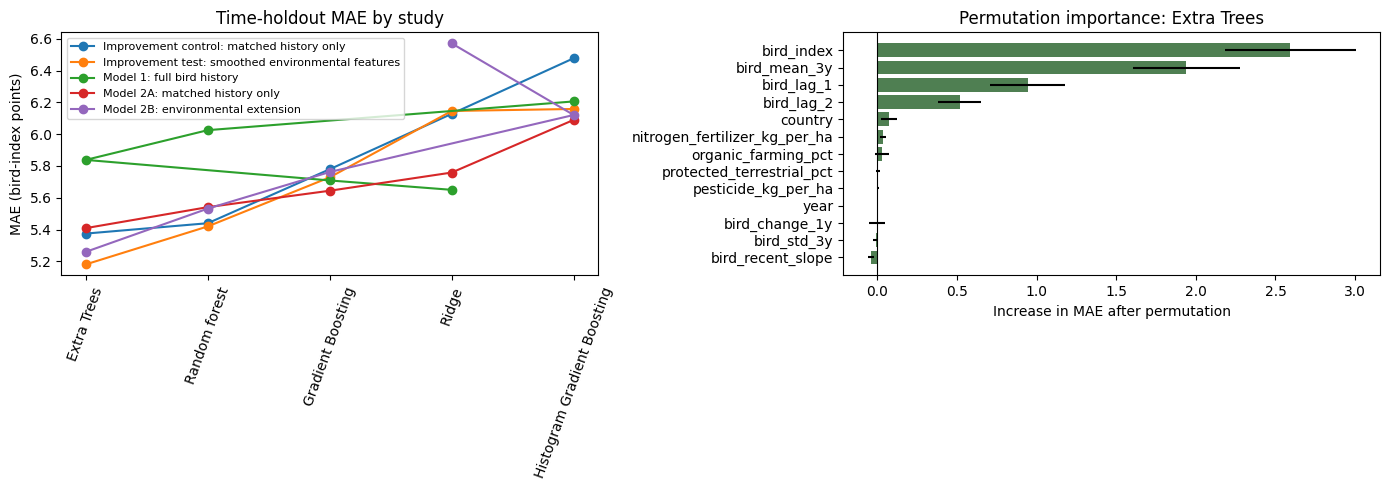

In [ ]:
from sklearn.inspection import permutation_importance


def best_cv_model(results, fitted):
    candidates = results.loc[results["model"] != "Persistence baseline"].copy()
    name = candidates.sort_values("cv_mae").iloc[0]["model"]
    return name, fitted[name].best_estimator_


# Create past-and-current 3-year environmental means without using future values.
improved_environment_panel = environmental_ml_panel.copy()
pressure_columns = [
    "organic_farming_pct", "pesticide_kg_per_ha",
    "protected_terrestrial_pct", "nitrogen_fertilizer_kg_per_ha",
]
for column in pressure_columns:
    improved_environment_panel[f"{column}_mean_3y"] = (
        improved_environment_panel
        .groupby("country")[column]
        .transform(lambda values: values.rolling(3, min_periods=2).mean())
    )

improved_environment_panel["log_pesticide_kg_per_ha_mean_3y"] = np.log1p(
    improved_environment_panel["pesticide_kg_per_ha_mean_3y"]
)
improved_environment_panel["log_nitrogen_fertilizer_kg_per_ha_mean_3y"] = np.log1p(
    improved_environment_panel["nitrogen_fertilizer_kg_per_ha_mean_3y"]
)

smoothed_environment_features = history_features + [
    "organic_farming_pct_mean_3y",
    "log_pesticide_kg_per_ha_mean_3y",
    "protected_terrestrial_pct_mean_3y",
    "log_nitrogen_fertilizer_kg_per_ha_mean_3y",
]
smoothed_environment_data = (
    improved_environment_panel
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=smoothed_environment_features + [target_column])
    .reset_index(drop=True)
)

smoothed_matched_history_results, _, _, _, _ = (
    evaluate_regression_study(
        smoothed_environment_data,
        history_features,
        "Improvement control: matched history only",
    )
)

smoothed_matched_history_results, _, _, _, _ = (
    evaluate_regression_study(
        smoothed_environment_data,
        history_features,
        "Improvement control: matched history only",
    )
)

smoothed_results, smoothed_fitted, _, smoothed_test, smoothed_split = (
    evaluate_regression_study(
        smoothed_environment_data,
        smoothed_environment_features,
        "Improvement test: smoothed environmental features",
    )
)

all_results = pd.concat([
    history_results,
    matched_history_results,
    environment_results,
    smoothed_matched_history_results,
    smoothed_results,
], ignore_index=True)

best_environment_name, best_environment_model = best_cv_model(
    environment_results, environment_fitted
)
importance = permutation_importance(
    best_environment_model,
    environment_test[environment_features],
    environment_test[target_column],
    scoring="neg_mean_absolute_error",
    n_repeats=30,
    random_state=42,
    n_jobs=1,
)
feature_importance = (
    pd.DataFrame({
        "feature": environment_features,
        "importance_mean": importance.importances_mean,
        "importance_std": importance.importances_std,
    })
    .sort_values("importance_mean", ascending=False, ignore_index=True)
)

display(all_results.style.format({
    "cv_mae": "{:.2f}", "test_mae": "{:.2f}", "test_rmse": "{:.2f}",
    "test_r2": "{:.3f}", "within_5_points": "{:.1%}",
}))
display(feature_importance)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_results = all_results.loc[all_results["model"] != "Persistence baseline"].copy()
for study, group in plot_results.groupby("study"):
    axes[0].plot(group["model"], group["test_mae"], marker="o", label=study)
axes[0].tick_params(axis="x", rotation=70)
axes[0].set(title="Time-holdout MAE by study", ylabel="MAE (bird-index points)")
axes[0].legend(fontsize=8)

importance_plot = feature_importance.sort_values("importance_mean")
axes[1].barh(
    importance_plot["feature"], importance_plot["importance_mean"],
    xerr=importance_plot["importance_std"], color="#4F7F52",
)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set(
    title=f"Permutation importance: {best_environment_name}",
    xlabel="Increase in MAE after permutation",
)
plt.tight_layout()
plt.show()


## 12.8 Programmatic interpretation and honest conclusion

The following summary distinguishes improvement on the matched sample from apparent differences caused by sample size. A positive percentage means the environmental extension reduced MAE. A negative value means it performed worse than the history-only comparator.

Even when an environmental variable receives high feature importance, this is **predictive association, not causation**. National annual observations are repeated measurements of countries, pesticide sales are not direct application, protected-area percentage does not measure farmland habitat quality, and bird monitoring methods differ between countries.


In [ ]:
def selected_cv_row(results):
    return (
        results.loc[results["model"] != "Persistence baseline"]
        .sort_values("cv_mae")
        .iloc[0]
    )


history_selected = selected_cv_row(history_results)
matched_selected = selected_cv_row(matched_history_results)
environment_selected = selected_cv_row(environment_results)
smoothed_control_selected = selected_cv_row(smoothed_matched_history_results)
smoothed_control_selected = selected_cv_row(smoothed_matched_history_results)
smoothed_selected = selected_cv_row(smoothed_results)

environment_gain_pct = (
    (matched_selected["test_mae"] - environment_selected["test_mae"])
    / matched_selected["test_mae"] * 100
)
smoothed_gain_pct = (
    (smoothed_control_selected["test_mae"] - smoothed_selected["test_mae"])
    / smoothed_control_selected["test_mae"] * 100
)

conclusion_table = pd.DataFrame({
    "comparison": [
        "Full bird-history forecasting",
        "Matched history-only",
        "Environmental extension",
        "Smoothed environmental experiment",
    ],
    "CV-selected model": [
        history_selected["model"], matched_selected["model"],
        environment_selected["model"], smoothed_selected["model"],
    ],
    "test MAE": [
        history_selected["test_mae"], matched_selected["test_mae"],
        environment_selected["test_mae"], smoothed_selected["test_mae"],
    ],
})

display(conclusion_table.style.format({"test MAE": "{:.2f}"}))
print(f"Environmental extension MAE improvement on matched rows: {environment_gain_pct:.1f}%")
print(f"Smoothed environmental MAE improvement on its matched rows: {smoothed_gain_pct:.1f}%")

if environment_gain_pct > 0:
    print("The environmental indicators add some holdout predictive value beyond bird history.")
else:
    print("The environmental indicators do not improve the post-2019 holdout over bird history alone.")

print(
    "Recommended next improvements: obtain longer harmonised pressure series; "
    "test biologically motivated 1–3 year lags; add habitat-specific agricultural-landscape "
    "measures; and validate with more countries or subnational observations. Avoid adding many "
    "features until the effective sample size grows."
)


,comparison,CV-selected model,test MAE
0,Full bird-history forecasting,Ridge,5.65
1,Matched history-only,Extra Trees,5.41
2,Environmental extension,Extra Trees,5.26
3,Smoothed environmental experiment,Extra Trees,5.18


Environmental extension MAE improvement on matched rows: 2.8%
Smoothed environmental MAE improvement on its matched rows: 3.6%
The environmental indicators add some holdout predictive value beyond bird history.
Recommended next improvements: obtain longer harmonised pressure series; test biologically motivated 1–3 year lags; add habitat-specific agricultural-landscape measures; and validate with more countries or subnational observations. Avoid adding many features until the effective sample size grows.


## 12.9 Final methodological decision

For the portfolio presentation, report **Model 1 as the primary forecasting result** because it uses the fuller bird panel. Present **Model 2 as a controlled feature-ablation experiment** asking whether broad environmental indicators improve that forecast.

The strongest claim supported by this design is predictive: whether environmental indicators improve out-of-time errors. It does not estimate the causal effect of pesticides, fertilisers, organic farming or protected areas on birds. Stronger causal claims would require better exposure measurements, explicit lag structures, controls for climate and habitat composition, and a panel/econometric design.


## 12.10 Validated result snapshot

The notebook code was run from a clean Python process after the corrections. The resulting modelling tables contained **568 country-years** for the full bird-history study and **177 country-years** for the complete environmental study.

| Study | CV-selected model | Post-2019 MAE | RMSE | R² |
|---|---|---:|---:|---:|
| Full bird history | Ridge | 5.65 | 9.51 | 0.75 |
| Full-history persistence baseline | Persistence | 6.14 | 10.08 | 0.72 |
| Matched history-only | Extra Trees | 5.41 | 8.99 | 0.70 |
| Environmental extension | Extra Trees | 5.26 | 8.81 | 0.72 |
| Smoothed environmental experiment | Extra Trees | 5.18 | 8.64 | 0.74 |

On identical rows, the direct environmental extension reduced MAE by approximately **2.8%** relative to the matched history-only model. The smoothed/log-transformed environmental experiment reduced MAE by approximately **3.6%** relative to its own history-only control. These are modest improvements rather than evidence of a large ecological effect.

Permutation importance showed that current and recent bird-index history dominated prediction. Nitrogen-fertiliser intensity supplied a small positive contribution; organic share and protected-area percentage were weaker, while pesticide intensity was close to zero in this one-year-ahead national model. This does not show that pesticides are ecologically unimportant: the sales-per-hectare proxy, national aggregation, reporting differences and delayed biological responses can hide a real relationship.


# 13. Feature–target relationships

Correlation is used here as an exploratory diagnostic, not as proof of causality. Two targets are examined:

- **Next-year bird index**, which is naturally dominated by current bird-index level.
- **Next-year change**, calculated as next-year index minus current index. This removes much of the baseline level and is more relevant when looking for pressure-related associations, although it is noisier.

Pearson correlation describes linear association; Spearman correlation describes monotonic association and is less sensitive to extreme values. Country is excluded because its one-hot encoded categories do not have a meaningful numeric correlation scale.


,feature,pearson_with_next_index,spearman_with_next_index,pearson_with_next_change,spearman_with_next_change
6,bird_mean_3y,0.91,0.93,-0.07,-0.03
1,bird_index,0.89,0.94,-0.23,-0.09
2,bird_lag_1,0.87,0.89,-0.00,-0.01
3,bird_lag_2,0.85,0.88,0.03,0.06
7,bird_std_3y,0.40,0.30,-0.17,0.06
11,nitrogen_fertilizer_kg_per_ha,-0.35,-0.39,0.02,-0.07
5,bird_recent_slope,0.18,0.19,-0.47,-0.34
8,organic_farming_pct,-0.17,-0.11,-0.06,-0.06
0,year,-0.16,-0.17,0.03,0.01
10,protected_terrestrial_pct,0.12,0.04,0.11,0.13


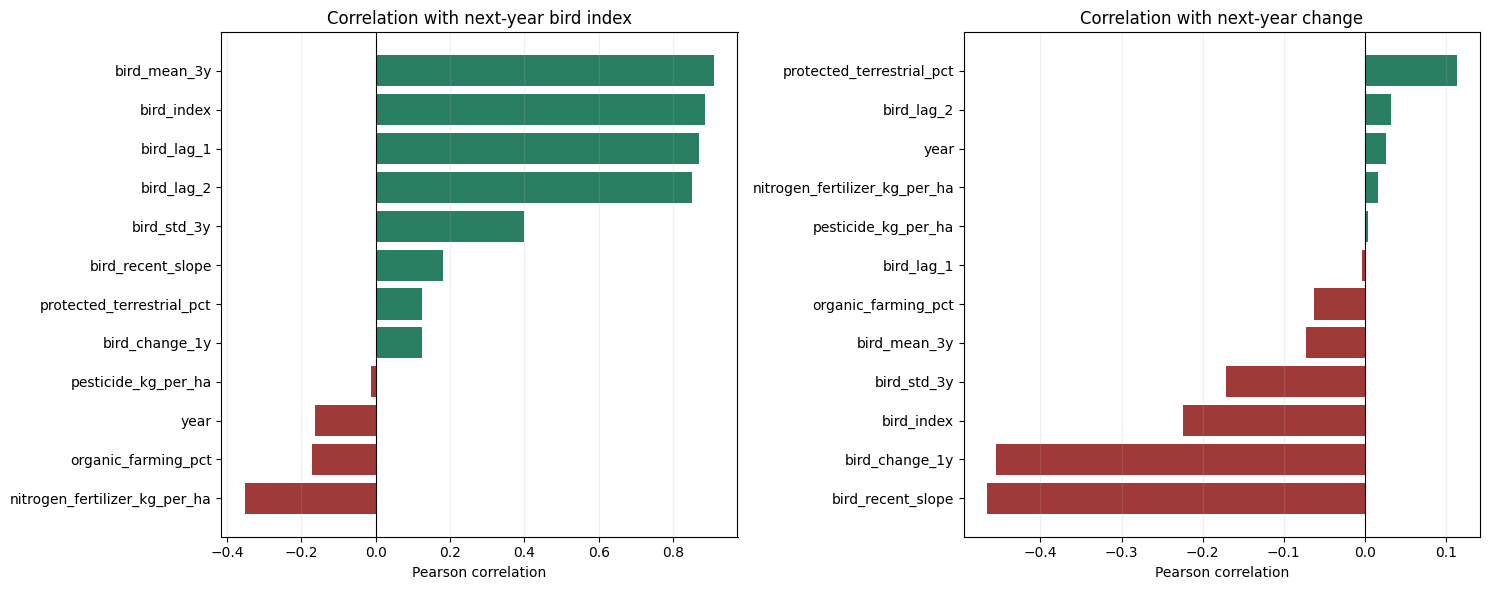

In [ ]:
correlation_data = environment_model_data.copy()
correlation_data["target_next_change"] = (
    correlation_data["target_next_bird_index"] - correlation_data["bird_index"]
)

correlation_features = [
    "year", "bird_index", "bird_lag_1", "bird_lag_2", "bird_change_1y",
    "bird_recent_slope", "bird_mean_3y", "bird_std_3y",
    "organic_farming_pct", "pesticide_kg_per_ha",
    "protected_terrestrial_pct", "nitrogen_fertilizer_kg_per_ha",
]
correlation_columns = correlation_features + [
    "target_next_bird_index", "target_next_change"
]

pearson_matrix = correlation_data[correlation_columns].corr(method="pearson")
spearman_matrix = correlation_data[correlation_columns].corr(method="spearman")

target_correlations = pd.DataFrame({
    "feature": correlation_features,
    "pearson_with_next_index": pearson_matrix.loc[
        correlation_features, "target_next_bird_index"
    ].to_numpy(),
    "spearman_with_next_index": spearman_matrix.loc[
        correlation_features, "target_next_bird_index"
    ].to_numpy(),
    "pearson_with_next_change": pearson_matrix.loc[
        correlation_features, "target_next_change"
    ].to_numpy(),
    "spearman_with_next_change": spearman_matrix.loc[
        correlation_features, "target_next_change"
    ].to_numpy(),
})

display(
    target_correlations
    .sort_values("pearson_with_next_index", key=lambda values: values.abs(), ascending=False)
    .round(3)
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for axis, target, title in [
    (axes[0], "pearson_with_next_index", "Correlation with next-year bird index"),
    (axes[1], "pearson_with_next_change", "Correlation with next-year change"),
]:
    plot_values = target_correlations.sort_values(target)
    colors = np.where(plot_values[target] >= 0, "#2A7F62", "#9F3A38")
    axis.barh(plot_values["feature"], plot_values[target], color=colors)
    axis.axvline(0, color="black", linewidth=0.8)
    axis.set(title=title, xlabel="Pearson correlation")
    axis.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()


## 13.1 Environmental correlation heatmap and scatter plots

The heatmap focuses on the four environmental indicators and both outcomes. The scatter plots include a simple least-squares line only to make the direction visible. They do not control for country, time, repeated observations or delayed effects.


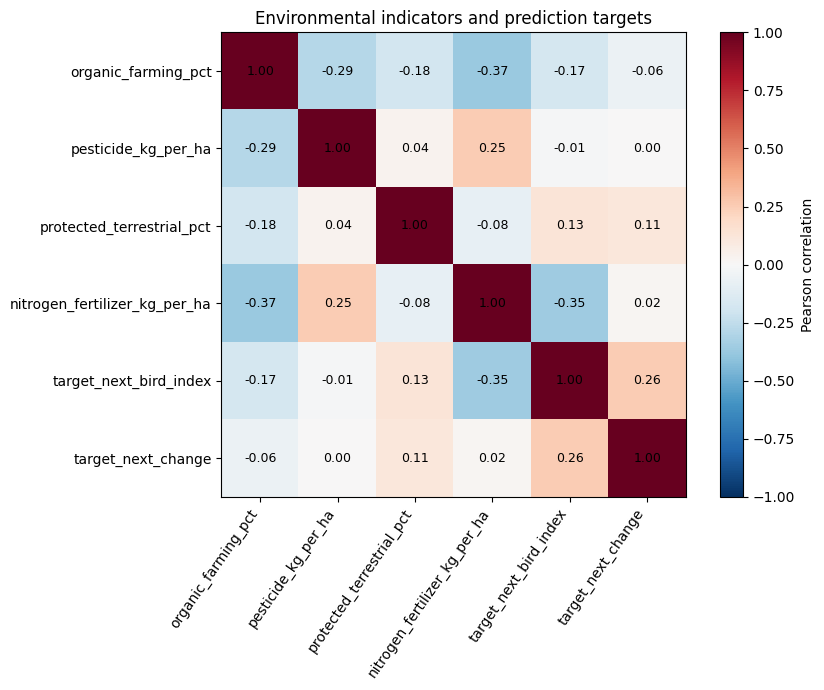

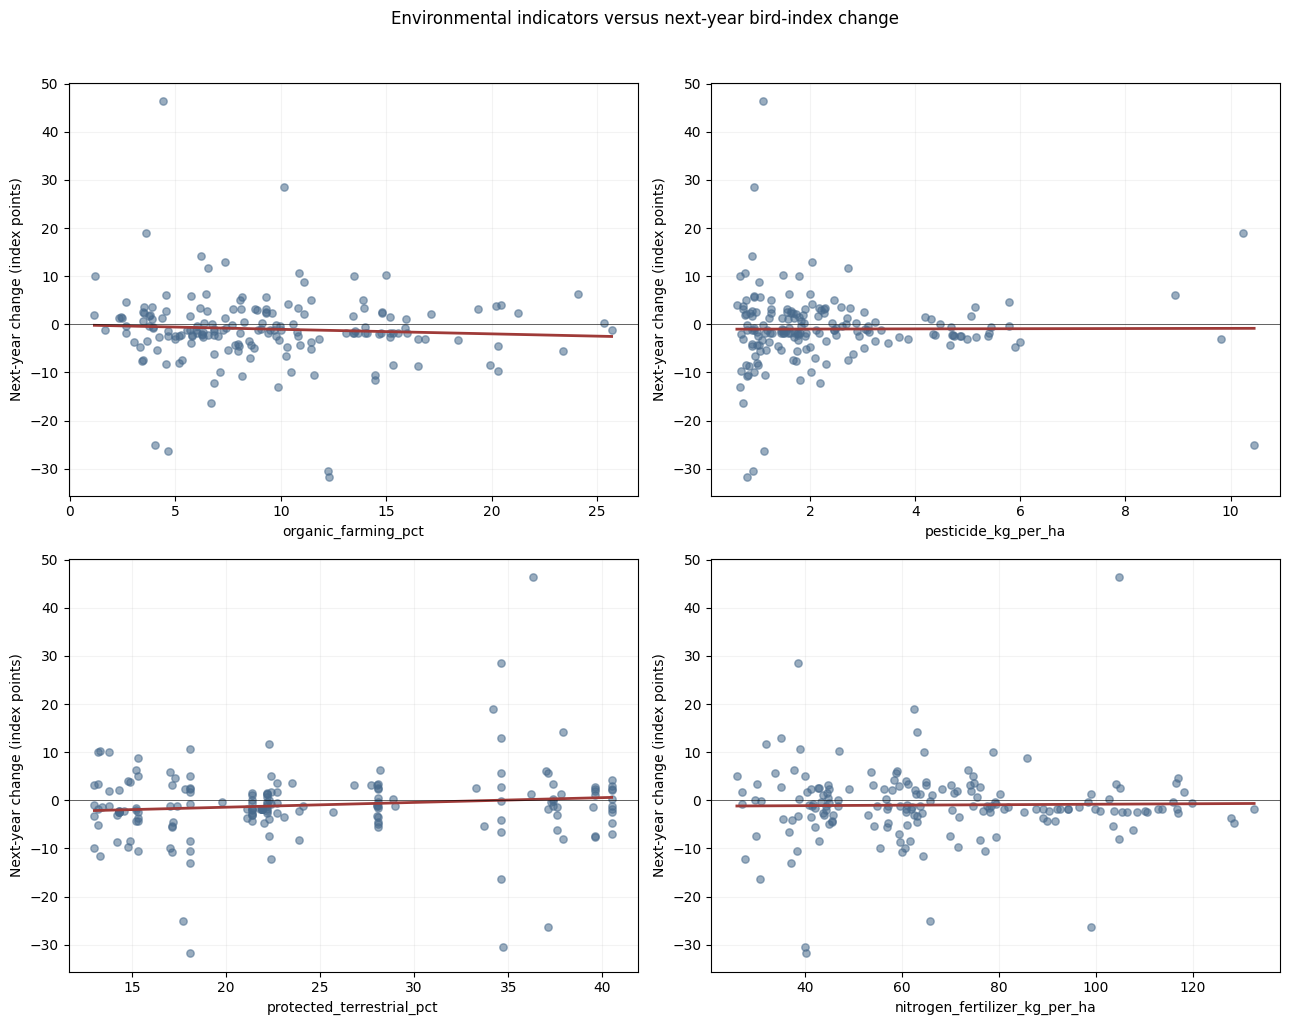

In [ ]:
environmental_correlation_columns = [
    "organic_farming_pct", "pesticide_kg_per_ha",
    "protected_terrestrial_pct", "nitrogen_fertilizer_kg_per_ha",
    "target_next_bird_index", "target_next_change",
]
environmental_corr = correlation_data[environmental_correlation_columns].corr()

fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(environmental_corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(environmental_correlation_columns)))
ax.set_yticks(range(len(environmental_correlation_columns)))
ax.set_xticklabels(environmental_correlation_columns, rotation=55, ha="right")
ax.set_yticklabels(environmental_correlation_columns)
for row in range(len(environmental_correlation_columns)):
    for column in range(len(environmental_correlation_columns)):
        value = environmental_corr.iloc[row, column]
        ax.text(column, row, f"{value:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(image, ax=ax, label="Pearson correlation")
ax.set_title("Environmental indicators and prediction targets")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for axis, feature in zip(axes.flat, environmental_correlation_columns[:4]):
    x = correlation_data[feature].astype(float).to_numpy()
    y = correlation_data["target_next_change"].astype(float).to_numpy()
    axis.scatter(x, y, alpha=0.55, s=28, color="#486A8C")
    if np.unique(x).size > 1:
        slope, intercept = np.polyfit(x, y, 1)
        line_x = np.linspace(np.nanmin(x), np.nanmax(x), 100)
        axis.plot(line_x, slope * line_x + intercept, color="#9F3A38", linewidth=2)
    axis.axhline(0, color="black", linewidth=0.7, alpha=0.6)
    axis.set(xlabel=feature, ylabel="Next-year change (index points)")
    axis.grid(alpha=0.15)
plt.suptitle("Environmental indicators versus next-year bird-index change", y=1.02)
plt.tight_layout()
plt.show()


# 14. Optional classification appendix — will the index decline next year?

This appendix preserves the useful classification component of the first version without replacing the more informative regression analysis. The target equals 1 when the next-year bird index is lower than the current index and 0 otherwise.

Because class proportions may be unequal, ordinary accuracy is reported but not used alone. **Balanced accuracy**, precision, recall, F1 and ROC-AUC are included. The confusion matrix shows the actual counts of correct and incorrect decline predictions.


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

classification_data = bird_history_model_data.copy()
classification_data["decline_next_year"] = (
    classification_data["target_next_bird_index"] < classification_data["bird_index"]
).astype("int8")

classification_train = classification_data.loc[
    classification_data["year"] < TEST_START_YEAR
].reset_index(drop=True)
classification_test = classification_data.loc[
    classification_data["year"] >= TEST_START_YEAR
].reset_index(drop=True)

X_train_cls = classification_train[history_features]
y_train_cls = classification_train["decline_next_year"]
X_test_cls = classification_test[history_features]
y_test_cls = classification_test["decline_next_year"]
classification_cv = make_temporal_cv(classification_train)
classification_preprocessor = make_preprocessor(history_features)

classification_specs = {
    "Logistic regression": (
        LogisticRegression(class_weight="balanced", max_iter=3000, random_state=42),
        {"model__C": [0.01, 0.1, 1.0, 10.0]},
    ),
    "Random forest classifier": (
        RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=1),
        {
            "model__n_estimators": [300],
            "model__max_depth": [3, None],
            "model__min_samples_leaf": [2, 5],
            "model__max_features": ["sqrt", 0.8],
        },
    ),
    "Extra Trees classifier": (
        ExtraTreesClassifier(class_weight="balanced", random_state=42, n_jobs=1),
        {
            "model__n_estimators": [300],
            "model__max_depth": [3, None],
            "model__min_samples_leaf": [2, 5],
            "model__max_features": ["sqrt", 0.8],
        },
    ),
    "Gradient Boosting classifier": (
        GradientBoostingClassifier(random_state=42),
        {
            "model__n_estimators": [100, 250],
            "model__learning_rate": [0.03, 0.08],
            "model__max_depth": [1, 2],
            "model__min_samples_leaf": [3, 6],
        },
    ),
}

dummy_classifier = Pipeline([
    ("preprocess", clone(classification_preprocessor)),
    ("model", DummyClassifier(strategy="most_frequent")),
])
dummy_classifier.fit(X_train_cls, y_train_cls)

classification_models = {"Most-frequent baseline": dummy_classifier}
classification_cv_scores = {"Most-frequent baseline": np.nan}

for model_name, (estimator, parameter_grid) in classification_specs.items():
    pipeline = Pipeline([
        ("preprocess", clone(classification_preprocessor)),
        ("model", clone(estimator)),
    ])
    search = GridSearchCV(
        pipeline,
        param_grid=parameter_grid,
        scoring="balanced_accuracy",
        cv=classification_cv,
        n_jobs=1,
        refit=True,
    )
    search.fit(X_train_cls, y_train_cls)
    classification_models[model_name] = search.best_estimator_
    classification_cv_scores[model_name] = search.best_score_


def classification_metric_row(model_name, model):
    prediction = model.predict(X_test_cls)
    probability = model.predict_proba(X_test_cls)[:, 1]
    return {
        "model": model_name,
        "cv_balanced_accuracy": classification_cv_scores[model_name],
        "test_accuracy": accuracy_score(y_test_cls, prediction),
        "test_balanced_accuracy": balanced_accuracy_score(y_test_cls, prediction),
        "test_precision": precision_score(y_test_cls, prediction, zero_division=0),
        "test_recall": recall_score(y_test_cls, prediction, zero_division=0),
        "test_f1": f1_score(y_test_cls, prediction, zero_division=0),
        "test_roc_auc": roc_auc_score(y_test_cls, probability),
    }


classification_results = pd.DataFrame([
    classification_metric_row(name, model)
    for name, model in classification_models.items()
]).sort_values("test_balanced_accuracy", ascending=False, ignore_index=True)

display(pd.Series({
    "training rows": len(classification_train),
    "test rows": len(classification_test),
    "training decline share": y_train_cls.mean(),
    "test decline share": y_test_cls.mean(),
}, name="value").to_frame())
display(classification_results.round(3))


,value
training rows,495.00
test rows,73.00
training decline share,0.62
test decline share,0.59


,model,cv_balanced_accuracy,test_accuracy,test_balanced_accuracy,test_precision,test_recall,test_f1,test_roc_auc
0,Logistic regression,0.67,0.66,0.65,0.71,0.70,0.71,0.66
1,Extra Trees classifier,0.63,0.62,0.64,0.78,0.49,0.60,0.64
2,Gradient Boosting classifier,0.61,0.63,0.58,0.64,0.86,0.73,0.67
3,Random forest classifier,0.67,0.57,0.56,0.64,0.65,0.64,0.60
4,Most-frequent baseline,NaN,0.59,0.50,0.59,1.00,0.74,0.50


## 14.1 Confusion matrices

The baseline matrix reveals what happens when every observation is assigned to the majority class. The selected model is chosen by pre-2019 temporal cross-validation, not by looking for the best post-2019 test result.


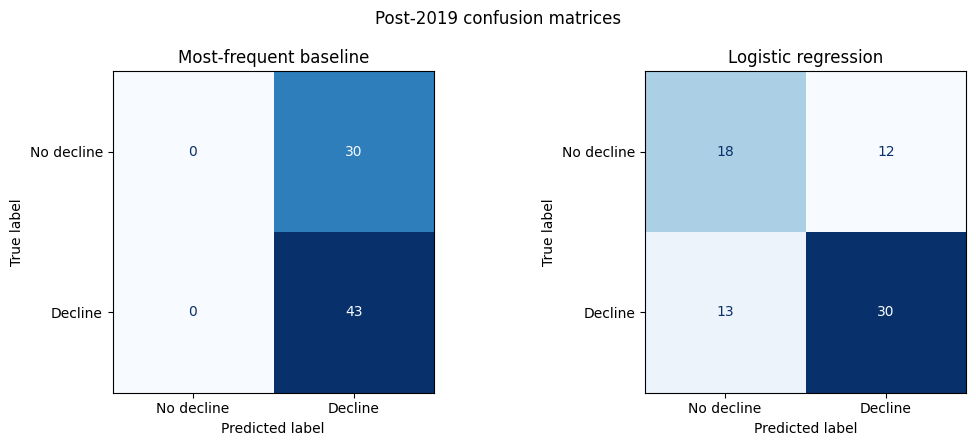

Classifier selected by temporal CV: Logistic regression


In [ ]:
cv_ranked_names = [
    name for name in classification_models
    if name != "Most-frequent baseline"
]
best_classifier_name = min(
    cv_ranked_names,
    key=lambda name: -classification_cv_scores[name],
)
best_classifier = classification_models[best_classifier_name]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for axis, name, model in [
    (axes[0], "Most-frequent baseline", dummy_classifier),
    (axes[1], best_classifier_name, best_classifier),
]:
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test_cls,
        y_test_cls,
        display_labels=["No decline", "Decline"],
        cmap="Blues",
        colorbar=False,
        ax=axis,
    )
    axis.set_title(name)
plt.suptitle("Post-2019 confusion matrices")
plt.tight_layout()
plt.show()

print(f"Classifier selected by temporal CV: {best_classifier_name}")


# 15. Presentation-ready conclusions

1. **Forecasting improved:** the full bird-history Ridge model reduced post-2019 MAE from 6.14 for persistence to 5.65, approximately an 8% reduction.
2. **Environmental information helped modestly:** on identical observations, Extra Trees reduced MAE from 5.41 using history alone to 5.26 after environmental indicators were added.
3. **Smoothing helped slightly more:** rolling environmental indicators reduced measurement noise, but their contribution remained much smaller than bird-history features.
4. **Advanced models were not automatically superior:** Ridge performed best for the larger history sample, while Extra Trees performed best in the smaller environmental sample. This supports choosing complexity through validation rather than model prestige.
5. **The classification appendix is secondary:** it communicates decline/no-decline errors through accuracy, balanced accuracy, F1 and confusion matrices, but regression remains the main analysis because it preserves the magnitude of change.
6. **No causal claim is made:** the project demonstrates out-of-time predictive associations using broad national indicators. Strong causal conclusions require finer habitat and exposure data, biologically motivated lags and a dedicated longitudinal causal design.

### Validated classification snapshot

Temporal cross-validation selected **Logistic Regression**. On the post-2019 test set it achieved accuracy **0.66**, balanced accuracy **0.65**, F1 **0.71**, and ROC-AUC **0.66**. The most-frequent baseline had accuracy **0.59** but balanced accuracy **0.50**, illustrating why ordinary accuracy alone is misleading. The selected model's confusion matrix contained 18 true non-declines, 12 false decline alarms, 13 missed declines, and 30 correctly detected declines.


## EXPORTING DATA FRAMES TO TABLEU FOR ANALYSIS AND PRESENTATION:

### 1. Environmental Bird ML Panel

In [ ]:
tableau_country_year_panel = (
    environmental_ml_panel[
        [
            "country",
            "year",
            "bird_index",
            "target_next_bird_index",
            "organic_farming_pct",
            "pesticide_kg_per_ha",
            "protected_terrestrial_pct",
            "nitrogen_fertilizer_kg_per_ha",
        ]
    ]
    .copy()
)

tableau_country_year_panel["target_next_change"] = (
    tableau_country_year_panel["target_next_bird_index"]
    - tableau_country_year_panel["bird_index"]
)

tableau_country_year_panel.to_csv(
    "tableau_country_year_panel.csv",
    index=False
)

In [ ]:
from google.colab import files
files.download('tableau_country_year_panel.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

###2. Export regression predictions

From the model selected by temporal cross-validation—Ridge, we export

In [ ]:
from pathlib import Path

tableau_output_dir = Path("outputs/tableau")
tableau_output_dir.mkdir(parents=True, exist_ok=True)

# Select the regression model with the lowest cross-validation MAE
best_history_model_name = (
    history_results
    .loc[history_results["model"] != "Persistence baseline"]
    .sort_values("cv_mae")
    .iloc[0]["model"]
)

best_history_model = (
    history_fitted[best_history_model_name]
    .best_estimator_
)

# Keep identification and observed-value columns
regression_test_predictions = history_test[
    [
        "country",
        "year",
        "bird_index",
        "target_next_bird_index",
    ]
].copy()

# The predictor year is year t; the predicted value belongs to year t+1
regression_test_predictions["prediction_year"] = (
    regression_test_predictions["year"] + 1
)

regression_test_predictions["model"] = (
    best_history_model_name
)

regression_test_predictions["predicted_next_bird_index"] = (
    best_history_model.predict(
        history_test[history_features]
    )
)

# Positive residual: model predicted too low
# Negative residual: model predicted too high
regression_test_predictions["residual"] = (
    regression_test_predictions["target_next_bird_index"]
    - regression_test_predictions["predicted_next_bird_index"]
)

regression_test_predictions["absolute_error"] = (
    regression_test_predictions["residual"].abs()
)

regression_test_predictions["squared_error"] = (
    regression_test_predictions["residual"] ** 2
)

regression_test_predictions["error_category"] = np.where(
    regression_test_predictions["absolute_error"] <= 5,
    "Within ±5 points",
    "More than 5 points error",
)

regression_test_predictions["prediction_direction"] = np.select(
    [
        regression_test_predictions["residual"] > 0,
        regression_test_predictions["residual"] < 0,
    ],
    [
        "Model predicted too low",
        "Model predicted too high",
    ],
    default="Exact prediction",
)

# Add the persistence baseline for comparison
regression_test_predictions["persistence_prediction"] = (
    regression_test_predictions["bird_index"]
)

regression_test_predictions["persistence_absolute_error"] = (
    regression_test_predictions["target_next_bird_index"]
    - regression_test_predictions["persistence_prediction"]
).abs()

regression_test_predictions.to_csv(
   "regression_test_predictions.csv",
    index=False,
)

print("Selected regression model:", best_history_model_name)
print("Exported rows:", len(regression_test_predictions))
print("Saved to:", "regression_test_predictions.csv")

display(regression_test_predictions.head())

Selected regression model: Ridge
Exported rows: 73
Saved to: regression_test_predictions.csv


,country,year,bird_index,target_next_bird_index,prediction_year,model,predicted_next_bird_index,residual,absolute_error,squared_error,error_category,prediction_direction,persistence_prediction,persistence_absolute_error
0,AT,2019,61.50,61.70,2020,Ridge,58.60,3.10,3.10,9.63,Within ±5 points,Model predicted too low,61.50,0.20
1,AT,2020,61.70,60.50,2021,Ridge,58.97,1.53,1.53,2.34,Within ±5 points,Model predicted too low,61.70,1.20
2,BE,2019,58.75,56.62,2020,Ridge,58.47,-1.85,1.85,3.40,Within ±5 points,Model predicted too high,58.75,2.13
3,CH,2019,105.65,117.65,2020,Ridge,99.77,17.88,17.88,319.69,More than 5 points error,Model predicted too low,105.65,12.00
4,CH,2020,117.65,119.19,2021,Ridge,107.15,12.04,12.04,145.04,More than 5 points error,Model predicted too low,117.65,1.54


In [ ]:
from google.colab import files
files.download('regression_test_predictions.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 3. Export classification predictions

Using the classifier selected by temporal cross-validation—Logistic Regression

In [ ]:
classification_test_predictions = (
    classification_test[
        [
            "country",
            "year",
            "bird_index",
            "target_next_bird_index",
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

classification_test_predictions["prediction_year"] = (
    classification_test_predictions["year"] + 1
)

classification_test_predictions["model"] = (
    best_classifier_name
)

classification_test_predictions["actual_decline"] = (
    y_test_cls
    .reset_index(drop=True)
    .astype(int)
)

classification_test_predictions["predicted_decline"] = (
    best_classifier.predict(X_test_cls).astype(int)
)

classification_test_predictions["decline_probability"] = (
    best_classifier.predict_proba(X_test_cls)[:, 1]
)

classification_test_predictions["actual_change"] = (
    classification_test_predictions["target_next_bird_index"]
    - classification_test_predictions["bird_index"]
)

classification_test_predictions["correct_prediction"] = np.where(
    classification_test_predictions["actual_decline"]
    == classification_test_predictions["predicted_decline"],
    "Correct",
    "Incorrect",
)

classification_test_predictions["confusion_category"] = np.select(
    [
        (
            classification_test_predictions["actual_decline"].eq(1)
            & classification_test_predictions["predicted_decline"].eq(1)
        ),
        (
            classification_test_predictions["actual_decline"].eq(0)
            & classification_test_predictions["predicted_decline"].eq(0)
        ),
        (
            classification_test_predictions["actual_decline"].eq(0)
            & classification_test_predictions["predicted_decline"].eq(1)
        ),
        (
            classification_test_predictions["actual_decline"].eq(1)
            & classification_test_predictions["predicted_decline"].eq(0)
        ),
    ],
    [
        "True Positive",
        "True Negative",
        "False Positive",
        "False Negative",
    ],
    default="Unknown",
)

classification_test_predictions.to_csv(
   "classification_test_predictions.csv",
    index=False,
)

print("Selected classifier:", best_classifier_name)
print("Exported rows:", len(classification_test_predictions))
print("Saved to:", "classification_test_predictions.csv")

display(classification_test_predictions.head())

Selected classifier: Logistic regression
Exported rows: 73
Saved to: classification_test_predictions.csv


,country,year,bird_index,target_next_bird_index,prediction_year,model,actual_decline,predicted_decline,decline_probability,actual_change,correct_prediction,confusion_category
0,AT,2019,61.50,61.70,2020,Logistic regression,0,0,0.50,0.20,Correct,True Negative
1,AT,2020,61.70,60.50,2021,Logistic regression,1,1,0.51,-1.20,Correct,True Positive
2,BE,2019,58.75,56.62,2020,Logistic regression,1,1,0.64,-2.13,Correct,True Positive
3,CH,2019,105.65,117.65,2020,Logistic regression,0,1,0.54,12.00,Incorrect,False Positive
4,CH,2020,117.65,119.19,2021,Logistic regression,0,0,0.50,1.54,Correct,True Negative


In [ ]:
from google.colab import files
files.download('classification_test_predictions.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>